# Can quantum-inspired orthogonal layers preserve certified robustness?

This notebook studies whether **orthogonality can make Lipschitz-constrained neural networks more useful in practice**, both when training a model from scratch and when adapting a pretrained model to a new task.

A network $f$ is $L$-Lipschitz if

$$
\|f(x)-f(x')\|_2 \leq L\|x-x'\|_2.
$$

Controlling $L$ limits how much the output can change under a bounded perturbation of the input, which makes it possible to derive **provable robustness certificates**. However, imposing the same Lipschitz bound does not mean that two networks behave in the same way internally.

The key difference studied here is between **spectral normalisation** and **orthogonality**. Spectral normalisation constrains only the largest singular value,

$$
\sigma_{\max}(W)=1,
$$

while the remaining singular values may be smaller than $1$. Repeating such layers can therefore progressively contract the representation as the network becomes deeper.

An orthogonal matrix instead satisfies

$$
W^\top W=I,
$$

so all its singular values are exactly $1$. It is therefore 1-Lipschitz while preserving the norm of every direction.

## Hypothesis

We test the hypothesis that this stronger geometric constraint can preserve useful information and certified robustness better than simply constraining $\sigma_{\max}$.

In particular, we expect orthogonality to matter in two situations:

1. **As depth increases:** small contractions introduced by individual layers can accumulate through the network, while orthogonal layers remain norm preserving.
2. **During fine-tuning:** unconstrained updates can change the singular values of a certified backbone and therefore its Lipschitz bound, while orthogonal transformations can adapt the representation without changing its singular-value spectrum.

## Why a quantum-inspired layer?

The orthogonal transformation used in this notebook is parameterised as a **butterfly circuit of Givens rotations**.

This has a direct quantum interpretation. In the unary basis, an RBS (Reconfigurable Beam Splitter) gate acts as a Givens rotation, and a circuit of RBS gates therefore implements an orthogonal transformation on that subspace.

The experiments themselves are simulated classically. The quantum-inspired perspective provides a structured parameterisation in which orthogonality is satisfied **by construction**, for every value of the trainable angles.

This lets us ask whether the geometry naturally implemented by these quantum circuits provides a useful inductive bias for robust learning.

## Two experiments

We test the hypothesis from two complementary angles.

### 1. Training from scratch: does orthogonality survive depth?

We train the same architecture at increasing depths and change only the channel-mixing operation:

* `dense`: unconstrained dense mixing,
* `dense-sn`: dense mixing with spectral normalisation,
* `butterfly`: orthogonal mixing using the quantum-inspired butterfly circuit.

The architecture is deliberately constructed so that the mixer is the only component that can introduce contraction. This allows us to measure how the different constraints affect information preservation, Lipschitz bounds, certified radii, and robustness as depth increases.

### 2. Fine-tuning: can a certificate survive adaptation?

We then start from a pretrained **certified backbone** and adapt it to a different classification task.

We compare four strategies:

* training only a new classification head,
* adding orthogonal butterfly adapters,
* LoRA,
* ordinary full fine-tuning.

The question is no longer whether we can build a certified model from scratch, but whether we can **adapt an existing certified model without losing the property that made it certifiable**.

Together, these experiments test the same idea at two stages of the model lifecycle: first when learning the representation, and then when adapting that representation to a new task.

### On two datasets

Sections 5 and 6 run both experiments on MNIST, where every arm can reach 98% and the
only thing that varies is the geometry. Section 7 then repeats both on
**DermaMNIST** — RGB dermatoscopic images, 7 lesion classes, 67% of which are
melanocytic nevi — to check whether the effect is an artefact of a clean, balanced,
two-class problem. It is not, and the harder dataset also exposes a trade-off that
MNIST hides.


In [1]:
import math, os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from experiments import (ADAPT_CSV, ATTACK_STRENGTH_CSV, BASELINE_CSV,
                         BASELINE_PERTURBATION_CSV, DEPTH_CSV, DEPTHS,
                         DERMA_ADAPT_CSV, DERMA_DEPTH_CSV, DERMA_DEPTHS,
                         DERMA_PERTURBATION_CSV, DERMA_TIGHTNESS_CSV,
                         DERMA_TIGHTNESS_IMAGES_CSV, MODES, PERTURBATION_CSV,
                         PIPELINE_CSV,
                         SEMANTIC_CSV, TIGHTNESS_CSV, TIGHTNESS_IMAGES_CSV,
                         resolve_device)
from core import ARMS, ButterflyOrthogonal, Dense1x1, DepthNet, num_butterfly_angles

RUN = False          # True = retrain everything; False = load results/*.csv
DATASET = 'mnist35'  # MNIST digits 3 vs 5 (sections 5-6)
SEEDS, EPOCHS = 2, 10
DERMA_EPOCHS = 30    # DermaMNIST (section 7) is harder and needs longer

# One colour per arm, used consistently in every figure.
C = {'dense': '#444444', 'dense-sn': '#1f77b4', 'butterfly': '#d62728'}
L = {'dense': 'dense (unconstrained)', 'dense-sn': 'dense + spectral norm',
     'butterfly': 'butterfly (quantum orthogonal)'}

pd.set_option('display.width', 200)
print('device:', resolve_device())

device: mps


# 1. The architecture

To isolate the effect of orthogonality, we use the **same network in every experiment** and vary only two things:

1. the type of channel-mixing layer;
2. the number of times that layer is repeated, which we call the **depth**.

The architecture is intentionally simple. Most operations are exact isometries, and the remaining ones are provably 1-Lipschitz. This keeps the Lipschitz accounting transparent and makes the mixer the only learned transformation whose singular-value spectrum differs between experimental arms.

Starting from a $28\times28$ grayscale image:

```text
input: (B, 1, 28, 28)

zero-pad to 32x32
        ↓
pixel_unshuffle ×3
1×32×32 → 4×16×16 → 16×8×8 → 64×4×4
        ↓
repeat `depth` times:
    64 → 64 channel mixer
    GroupSort
    Roll
        ↓
flatten: 64×4×4 = 1024 features
        ↓
spectrally-normalised linear classifier
```

Each operation has a specific role:

* **Zero-padding** embeds the input into a larger tensor without changing its $L_2$ norm.
* **Pixel unshuffle** rearranges tensor entries, so it is an exact isometry. After three applications, each spatial position contains 64 channels representing an $8\times8$ region of the original image.
* **GroupSort** sorts pairs of channels. It preserves the norm of each activation vector and is 1-Lipschitz, unlike ReLU, which can discard activation norm.
* **Roll** is a permutation used to exchange information between spatial groups that would otherwise remain separated by the pixel-unshuffle structure.
* The final **linear classifier** is divided by its largest singular value, giving it spectral norm $1$.

`GroupSort` is not invertible and can still reduce the distance between two different inputs. Therefore, the full network is not an isometry. What this design controls is the **additional linear contraction introduced by the mixer**, which is the quantity we want to study as depth increases.

## 1.1 The three mixers

At every depth, we compare three versions of exactly the same network.

| Arm         | Mixer                                   | Lipschitz constraint | Singular values                   |
| ----------- | --------------------------------------- | -------------------- | --------------------------------- |
| `dense`     | Unconstrained $64\times64$ matrix       | None                 | Unconstrained                     |
| `dense-sn`  | Dense matrix divided by $\sigma_{\max}$ | $|W|_2=1$            | $\sigma_{\max}=1$, others $\leq1$ |
| `butterfly` | Product of Givens rotations             | $|W|_2=1$            | All exactly $1$                   |

The key comparison is between `dense-sn` and `butterfly`. Both have the **same upper Lipschitz bound**, but they achieve it in very different ways.

Spectral normalisation rescales a matrix as

$$
W_{\mathrm{SN}}=\frac{W}{\sigma_{\max}(W)}.
$$

This guarantees

$$
\sigma_{\max}(W_{\mathrm{SN}})=1,
$$

but places no lower constraint on the remaining singular values. Directions associated with singular values below $1$ are therefore contracted.

The butterfly mixer instead constructs $W$ as a product of Givens rotations. A rotation acting on coordinates $(i,j)$ has the form

$$
G(i,j,\theta)=
\begin{pmatrix}
\cos\theta & \sin\theta\\
-\sin\theta & \cos\theta
\end{pmatrix},
$$

with the identity on all remaining coordinates. Each rotation is orthogonal for every value of $\theta$, so their product satisfies

$$
W^\top W=I.
$$

Consequently,

$$
\sigma_1(W)=\cdots=\sigma_C(W)=1.
$$

Orthogonality therefore requires no projection, regularisation term, or post-training correction. The angles can be optimized directly while the matrix remains orthogonal throughout training.

For $C=2^m$ channels, the butterfly uses $m=\log_2 C$ levels. At level $\ell$, channels are paired according to

$$
j=i\oplus 2^\ell,
$$

giving a total of

$$
\frac{C}{2}\log_2 C
$$

trainable angles. For $C=64$, this is **192 angles**, compared with **4,096 parameters** in a dense $64\times64$ mixer.

This construction is also the quantum-inspired part of the model. In the unary basis, an RBS gate implements the same two-dimensional rotation, so the butterfly corresponds directly to a circuit of RBS gates. The experiments here implement the resulting orthogonal transformation classically.

## 1.2 Why use such a restricted architecture?

This network is **not intended to be a competitive image architecture**. It is a controlled experiment designed to make the effect of the mixer measurable.

In particular, it is neither a ResNet nor a fully connected MLP:

* There are **no residual connections**.
* There is **no batch normalisation**.
* There are **no $3\times3$ convolutions**.
* The $1\times1$ mixer acts on the 64 channels independently at each of the 16 spatial positions, with the same weights shared across positions.

These choices avoid introducing additional components whose Lipschitz behaviour would complicate the comparison.

A standard spatial convolution, for example, is not made orthogonal simply by normalising its kernel. Residual connections also change the Lipschitz accounting because for

$$
y=x+F(x),
$$

we generally obtain

$$
\operatorname{Lip}(y)\leq 1+\operatorname{Lip}(F),
$$

rather than the simple product of layer bounds used here. Batch normalisation introduces another input-dependent scaling factor that can substantially increase the global bound.

The architecture therefore trades realism for **experimental control**.

The conclusions should be interpreted at the level of the mechanism being tested: what happens when contractive or norm-preserving linear transformations are repeatedly composed. The numerical results for a given depth should not be interpreted as direct predictions for architectures such as ResNets, where convolutions, residual paths, and normalisation introduce additional effects.


In [2]:
# The three arms at depth 4, side by side.
rows = []
for arm in ARMS:
    torch.manual_seed(0)
    m = DepthNet(num_classes=2, arm=arm, depth=4)
    rows.append({'arm': arm, 'mixer params': m.mixer_parameters(),
                 'total params': sum(p.numel() for p in m.parameters()),
                 'L_analytic at init': round(m.analytic_lipschitz(), 4)})

print('A single 64-channel mixer:')
print(f'   dense / dense-sn : 64 x 64          = {64*64:>5d} parameters')
print(f'   butterfly        : (64/2) * log2(64) = {num_butterfly_angles(64):>5d} angles'
      f'   ({64*64/num_butterfly_angles(64):.0f}x fewer)')
print()
pd.DataFrame(rows)

A single 64-channel mixer:
   dense / dense-sn : 64 x 64          =  4096 parameters
   butterfly        : (64/2) * log2(64) =   192 angles   (21x fewer)



,arm,mixer params,total params,L_analytic at init
0,dense,16640,18690,1.0
1,dense-sn,16640,18690,1.0
2,butterfly,1024,3074,1.0


# 2. The effect of depth

The difference between spectral normalisation and orthogonality becomes more important as layers are composed.

If a layer contracts a relevant direction by a factor $\sigma<1$, repeated contraction can accumulate approximately as

$$
\sigma^d,
$$

where $d$ is the network depth.

This is the effect we test next: whether spectrally normalised mixers progressively lose useful signal as depth increases, while orthogonal butterfly mixers avoid this source of contraction.


In [3]:
torch.manual_seed(0)

dense_sn = Dense1x1(64, normalise=True)
with torch.no_grad():
    dense_sn.weight.normal_(0, 3.0)      # a generic matrix

butterfly = ButterflyOrthogonal(64)
with torch.no_grad():
    butterfly.theta.normal_(0, 3.0)      # arbitrary angles

for name, layer in (('dense + spectral norm', dense_sn), ('butterfly', butterfly)):
    smax, smin = layer.singular_values()
    print(f'{name:24s}  sigma_max = {smax:.6f}   sigma_min = {smin:.6f}')

# How a per-layer contraction compounds. The sigma_min values here bracket what
# the trained dense-sn layers actually reach (section 5.2 measures 0.23 - 0.41).
print('\nfraction of the worst direction surviving a stack of d such layers:\n')
compounding = pd.DataFrame(
    {f'sigma_min = {s}': [f'{s ** d:.2e}' for d in DEPTHS] for s in (0.9, 0.7, 0.5, 0.3)},
    index=pd.Index(DEPTHS, name='depth'))
compounding['orthogonal (sigma = 1)'] = [f'{1.0 ** d:.2e}' for d in DEPTHS]
compounding

dense + spectral norm     sigma_max = 1.000000   sigma_min = 0.011881
butterfly                 sigma_max = 1.000000   sigma_min = 1.000000

fraction of the worst direction surviving a stack of d such layers:



,sigma_min = 0.9,sigma_min = 0.7,sigma_min = 0.5,sigma_min = 0.3,orthogonal (sigma = 1)
depth,,,,,
4,6.56e-01,2.40e-01,6.25e-02,8.10e-03,1.00e+00
8,4.30e-01,5.76e-02,3.91e-03,6.56e-05,1.00e+00
16,1.85e-01,3.32e-03,1.53e-05,4.30e-09,1.00e+00
32,3.43e-02,1.10e-05,2.33e-10,1.85e-17,1.00e+00
64,1.18e-03,1.22e-10,5.42e-20,3.43e-34,1.00e+00
128,1.39e-06,1.49e-20,2.94e-39,1.18e-67,1.00e+00


# 3. The experiment

We now test whether the difference between spectral normalisation and orthogonality becomes more important as depth increases.

### Data

We use **MNIST 3 vs 5**, a binary classification task with 11,552 training and 1,902 test images.

Pixels are scaled to $[0,1]$, with no augmentation or mean/std normalisation. This keeps perturbation norms directly interpretable in the original input space.

Clean accuracy is evaluated on the full test set. More expensive measurements, such as margins and adversarial attacks, use the same fixed subset of 2,000 test images for every model.

### Experimental grid

We train:

* 3 mixer types: `dense`, `dense-sn`, and `butterfly`
* 6 depths: $4, 8, 16, 32, 64, 128$
* 2 random seeds

for a total of **36 models**.

All models are trained for 10 epochs using Adam with learning rate $10^{-3}$ and batch size 128.

### Loss

A standard cross-entropy loss is not ideal when logits are constrained to remain $O(1)$ by a 1-Lipschitz network. We therefore compute cross-entropy on

$$
8\left(z-\mathrm{onehot}(y)\right),
$$

where $z$ denotes the model logits.

This transformation is used **only inside the loss**. It does not modify the forward pass used at inference time and therefore does not change the model's Lipschitz bound. The same loss is used for all three mixer types.

## 3.1 What we measure

| Quantity                             | What it tells us                                                                                                                                                           |
| ------------------------------------ | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Clean accuracy**                   | Classification accuracy on the full test set.                                                                                                                              |
| **Norm retention**                   | $|h_{\mathrm{out}}|*2 / |h*{\mathrm{in}}|_2$ across the mixer stack. Measures how much activation norm survives through depth.                                             |
| **$L_{\mathrm{analytic}}$**          | Global $L_2$ Lipschitz upper bound obtained by multiplying the layer bounds. All non-mixer components have bound $1$, so differences come from the mixers.                 |
| **Certified radius**                 | For a correctly classified sample, $r(x)=M(x)/(\sqrt{2}L)$, where $M(x)$ is its logit margin. Perturbations with $|d|_2<r(x)$ are guaranteed not to change the prediction. |
| **$\sigma_{\max}$, $\sigma_{\min}$** | Largest and smallest singular values of the trained mixers, computed by SVD after training.                                                                                |
| **Bound check**                      | Numerically verifies $|f(x+d)-f(x)|_2\leq L|d|_2$ on random input pairs and perturbation scales.                                                                           |
| **Collapsed**                        | Indicates that accuracy does not exceed the majority-class baseline. Robustness metrics are not meaningful for such a model.                                               |

The certified radius depends on both **margin** and **Lipschitz constant**. Simply shrinking all logits does not artificially improve it, because the margin and $L$ scale together.

## 3.2 Random noise vs adversarial perturbations

A robustness certificate concerns the **worst possible perturbation direction**, not a typical random one.

This distinction matters in high dimensions. For an input dimension $d$, a random direction has expected alignment of order

$$
\frac{1}{\sqrt{d}}.
$$

For MNIST, $d=784$, giving approximately

$$
\frac{1}{\sqrt{784}}\approx0.036.
$$

Random noise therefore probes average-case sensitivity, while an adversarial attack actively searches for damaging directions.

To compare them fairly, we keep the perturbation norm fixed,

$$
\|d\|_2=\epsilon,
$$

and vary only how its direction is chosen:

| Test          | Perturbation                                                                                                                        |
| ------------- | ----------------------------------------------------------------------------------------------------------------------------------- |
| **Random**    | Gaussian direction rescaled to have exactly norm $\epsilon$. Four independent draws are tested.                                     |
| **PGD-$L_2$** | Projected gradient ascent on the classification margin, using 50 steps and 2 restarts inside the $L_2$ ball of radius $\epsilon$.   |
| **Certified** | Fraction of samples that are both correctly classified and have $r(x)>\epsilon$. This is a provable lower bound on robust accuracy. |

Using exact $L_2$ norm is important. A Gaussian perturbation with per-pixel standard deviation $\sigma$ has expected norm approximately

$$
\sigma\sqrt{784}=28\sigma,
$$

so a sweep over $\sigma$ would not be directly comparable to an $\epsilon$-bounded adversarial attack.

Finally, perturbations are **not clipped to $[0,1]$**. The certificate applies to the full $L_2$ ball around each input, so clipping would evaluate a weaker threat model than the one being certified.


---
# 4. Run or load

In [4]:
if RUN:
    # Regenerates every number in this notebook: the depth study of section 5 and
    # the fine-tuning study of section 6. Roughly an hour on an M-series GPU.
    from experiments import run_adaptation_grid, run_grid
    for path in (DEPTH_CSV, PERTURBATION_CSV, ADAPT_CSV):
        if os.path.exists(path):
            os.remove(path)
    run_grid(dataset=DATASET, seeds=SEEDS, epochs=EPOCHS)
    run_adaptation_grid(seeds=SEEDS, epochs=EPOCHS)

depth = pd.read_csv(DEPTH_CSV)
pert = pd.read_csv(PERTURBATION_CSV)

print(f'{len(depth)} trained models, {len(pert)} perturbation measurements')
assert depth['bound_respected'].all(), 'a Lipschitz bound was violated'
print('every analytic bound was respected on every model')
depth.head()

36 trained models, 324 perturbation measurements
every analytic bound was respected on every model


,dataset,arm,depth,seed,epochs,clean_accuracy,balanced_accuracy,n_predicted_classes,norm_retention,L_analytic,median_margin,certified_radius,mixer_params,mixer_sigma_max,mixer_sigma_min,bound_respected,worst_observed_ratio,majority_class_rate,collapsed,seconds
0,mnist35,dense,4,0,10,0.992639,0.992742,2,1.935617,13.476393,5.458230,0.286393,16640,2.244060,0.637303,True,0.376347,0.53102,False,6.304980
1,mnist35,dense,4,1,10,0.992114,0.991919,2,1.970610,14.468884,5.509684,0.269263,16640,2.113981,0.694117,True,0.341368,0.53102,False,5.810413
2,mnist35,dense-sn,4,0,10,0.989485,0.989641,2,0.796218,1.000000,1.917797,1.356087,16640,1.000000,0.329549,True,0.099056,0.53102,False,7.890206
3,mnist35,dense-sn,4,1,10,0.990536,0.990565,2,0.832711,1.000000,1.919688,1.357424,16640,1.000000,0.372047,True,0.092341,0.53102,False,7.207505
4,mnist35,butterfly,4,0,10,0.980547,0.980832,2,1.004917,1.000000,1.817151,1.284920,1024,1.000000,1.000000,True,0.110350,0.53102,False,10.261400


In [5]:
# The unconstrained reference used in every figure from here on: an ordinary
# conv-BN-ReLU CNN trained on the same data with the same budget. It has no
# Lipschitz bound and no certificate, so it is not a fourth arm -- it is a ruler,
# so that "the accuracy is low" can be read against something. §7.5 gives the full
# grid it comes from, including what the certificate costs.
bl = pd.read_csv(BASELINE_CSV)
bl_pert = pd.read_csv(BASELINE_PERTURBATION_CSV)
CNN_C = '#2ca02c'
CNN_LABEL = 'unconstrained CNN (no certificate)'

def _cnn_rows(frame, dataset, class_weights, augment, schedule):
    m = ((frame.dataset == dataset) & (frame.class_weights == class_weights)
         & (frame.augment == augment) & (frame.schedule == schedule))
    if 'model' in frame:
        m &= frame.model == 'simple-cnn'
    return frame[m]

def cnn_ref(dataset, class_weights=False, augment=False, schedule=False):
    """(plain, balanced) accuracy of the CNN under a matched training recipe."""
    r = _cnn_rows(bl, dataset, class_weights, augment, schedule)
    return float(r.clean_accuracy.mean()), float(r.balanced_accuracy.mean())

def cnn_curve(dataset, field, class_weights=False, augment=False, schedule=False):
    """The CNN's accuracy vs perturbation norm, under the same two attacks."""
    r = _cnn_rows(bl_pert, dataset, class_weights, augment, schedule)
    return r.groupby('epsilon')[field].mean()

def cnn_line(ax, value, label=CNN_LABEL):
    """A dashed green reference line at the CNN's accuracy."""
    ax.axhline(value, color=CNN_C, ls='--', lw=1.5, label=label)
    return ax

print('CNN reference   mnist35            plain %.4f   balanced %.4f' % cnn_ref('mnist35'))
print('CNN reference   mnist08            plain %.4f   balanced %.4f' % cnn_ref('mnist08'))
print('CNN reference   dermamnist (w)     plain %.4f   balanced %.4f'
      % cnn_ref('dermamnist', class_weights=True))

CNN reference   mnist35            plain 0.9963   balanced 0.9961
CNN reference   mnist08            plain 0.9992   balanced 0.9992
CNN reference   dermamnist (w)     plain 0.6170   balanced 0.5660


In [6]:
# Mean over seeds. `collapsed` marks models that became constant predictors.
agg = (depth.groupby(['arm', 'depth'])
            .agg(clean_accuracy=('clean_accuracy', 'mean'),
                 balanced_accuracy=('balanced_accuracy', 'mean'),
                 norm_retention=('norm_retention', 'mean'),
                 L_analytic=('L_analytic', 'mean'),
                 certified_radius=('certified_radius', 'mean'),
                 sigma_min=('mixer_sigma_min', 'mean'),
                 mixer_params=('mixer_params', 'first'),
                 collapsed=('collapsed', 'any'))
            .reset_index())

def table(column, fmt='{:.4f}'):
    """Pivot one column into an arm x depth table."""
    t = agg.pivot(index='depth', columns='arm', values=column)
    return t[list(ARMS)].map(lambda v: fmt.format(v) if pd.notna(v) else '--')

def plot(column, ylabel, logy=False, ax=None, show_collapsed=True, legend=True):
    """One line per arm.

    A collapsed model is drawn as isolated crosses, never joined to the live part
    of its line. Joining them would show the collapse as a recovery: `dense-sn`
    scores 0.53 at depth 64 only because it answers the same class for every
    input, which is trivially unflippable and not robustness.
    """
    ax = ax or plt.subplots(figsize=(6.4, 4.3))[1]
    for arm in ARMS:
        s = agg[agg.arm == arm].sort_values('depth')
        live, dead = s[~s.collapsed], s[s.collapsed]
        ax.plot(live['depth'], live[column], '-o', color=C[arm], label=L[arm], lw=1.8, ms=5)
        if len(dead) and show_collapsed:
            ax.plot(dead['depth'], dead[column], 'x', color=C[arm], ms=9, mew=2.2,
                    ls='none', label=L[arm] + ' — collapsed (constant predictor)')
        elif len(dead):
            for d_ in dead['depth']:
                ax.axvline(d_, color=C[arm], ls=':', lw=1, alpha=0.5)
    ax.set_xscale('log', base=2); ax.set_xticks(DEPTHS)
    ax.set_xticklabels([str(d) for d in DEPTHS])
    if logy: ax.set_yscale('log')
    ax.set_xlabel('depth (number of mixing layers)'); ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3, which='both')
    if legend: ax.legend(fontsize=8)
    return ax

agg.round(4)

,arm,depth,clean_accuracy,balanced_accuracy,norm_retention,L_analytic,certified_radius,sigma_min,mixer_params,collapsed
0,butterfly,4,0.9805,0.9807,1.0067,1.000000e+00,1.2809,1.0000,1024,False
1,butterfly,8,0.9813,0.9814,1.0172,1.000000e+00,1.3052,1.0000,2048,False
2,butterfly,16,0.9837,0.9837,1.0225,1.000000e+00,1.3458,1.0000,4096,False
3,butterfly,32,0.9848,0.9849,0.9807,1.000000e+00,1.3668,1.0000,8192,False
4,butterfly,64,0.9837,0.9840,1.0140,1.000000e+00,1.3692,1.0000,16384,False
5,butterfly,128,0.9837,0.9839,1.0510,1.000000e+00,1.3525,1.0000,32768,False
6,dense,4,0.9924,0.9923,1.9531,1.397260e+01,0.2778,0.6657,16640,False
7,dense,8,0.9905,0.9908,2.1616,4.827250e+01,0.1069,0.6860,33280,False
8,dense,16,0.9890,0.9888,2.3033,2.393732e+02,0.0256,0.6347,66560,False
9,dense,32,0.9866,0.9864,3.3965,6.501802e+03,0.0015,0.5852,133120,False


# 5. Results

**Two metrics and a ruler, in every figure from here on.** Every accuracy is reported twice:
**plain accuracy**, the fraction of test images classified correctly, and **balanced
accuracy**, the mean of the per-class recalls. On MNIST they agree, because the two classes
are 53/47. On DermaMNIST they disagree sharply, and the gap between them is itself the
finding — see §7.5. Every figure also carries a dashed green line for an **ordinary
unconstrained CNN** trained on the same data with the same budget: not a fourth arm, since it
has no certificate and cannot have one, but a ruler, so that an accuracy can be read against
something rather than against nothing.

## 5.1 Clean accuracy: orthogonality remains trainable at depth

All three models learn well at shallow depths. The difference appears as the network becomes deeper.

* `dense` remains above 98% accuracy at every depth.
* `butterfly` remains stable at about 98% up to depth 128.
* `dense-sn` performs similarly up to depth 32, and then becomes unreliable. At depth 64 one of the two seeds collapses to **53.1%** — exactly the majority-class baseline — while the other still reaches 98.3%. At depth 128 both seeds collapse.

Therefore, in this architecture and training setup, spectral normalisation stops being *reliably* trainable beyond depth 32 and fails completely by depth 128, while the orthogonal parameterisation remains trainable throughout.

Two seeds are not enough to locate that transition precisely. What the data supports is that the failure is intermittent at depth 64 and total at depth 128 — not that there is a sharp threshold between them.


plain accuracy:


arm,dense,dense-sn,butterfly
depth,,,
4,0.9924,0.9900,0.9805
8,0.9905,0.9908,0.9813
16,0.9890,0.9903,0.9837
32,0.9866,0.9821,0.9848
64,0.9858,0.7568,0.9837
128,0.9848,0.5310,0.9837


balanced accuracy (mean per-class recall):


arm,dense,dense-sn,butterfly
depth,,,
4,0.9923,0.9901,0.9807
8,0.9908,0.9908,0.9814
16,0.9888,0.9904,0.9837
32,0.9864,0.9821,0.9849
64,0.9859,0.7414,0.9840
128,0.9842,0.5000,0.9839


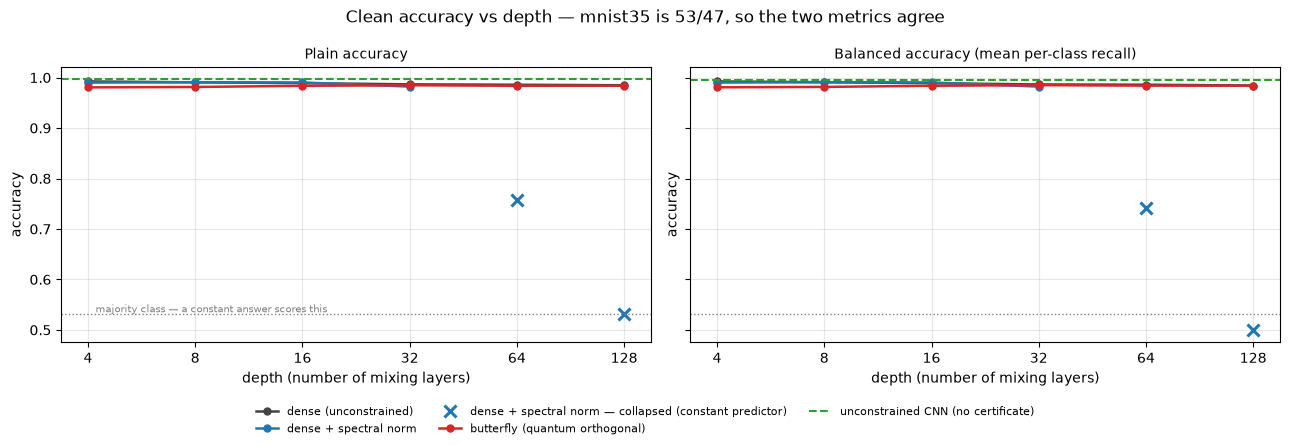

In [7]:
print('plain accuracy:')
display(table('clean_accuracy'))
print('balanced accuracy (mean per-class recall):')
display(table('balanced_accuracy'))

ref_plain, ref_bal = cnn_ref('mnist35')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, col, ref, title in ((axes[0], 'clean_accuracy', ref_plain, 'Plain accuracy'),
                            (axes[1], 'balanced_accuracy', ref_bal,
                             'Balanced accuracy (mean per-class recall)')):
    plot(col, 'accuracy', ax=ax, legend=False)
    cnn_line(ax, ref)
    ax.axhline(0.531, color='grey', ls=':', lw=1)
    ax.set_title(title, fontsize=10)
axes[0].text(4.2, 0.535, 'majority class — a constant answer scores this',
             color='grey', fontsize=7.5)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3,
           fontsize=8, frameon=False)
fig.suptitle('Clean accuracy vs depth — mnist35 is 53/47, so the two metrics agree')
fig.tight_layout(rect=(0, 0.09, 1, 1)); plt.show()

## 5.2 What happens to the activations?

Norm retention measures how much activation norm remains after the repeated mixer stack:

$$
\text{retention}=
\frac{\|h_{\mathrm{out}}\|_2}
{\|h_{\mathrm{in}}\|_2}.
$$

The three mixers behave very differently as depth increases:

* `dense-sn` falls from **0.81 at depth 4 to 0.07 at depth 128**. By the deepest model, only about 7% of the original activation norm reaches the end of the stack.
* `butterfly` stays close to **1** at every depth, as expected from its norm-preserving construction.
* `dense` has retention above **1**, because unconstrained weights are free to amplify activations.

The singular values show the same pattern. After training, the smallest singular value of `dense-sn` layers is typically around $0.18$-$0.37$, while it remains exactly $1$ for the butterfly layers.

The strong contraction of `dense-sn` therefore accumulates with depth, and coincides with the loss of trainability at depths 64 and 128. Note that the seed which *did* train at depth 64 retained 0.29 of the activation norm, against 0.07 for the seed that collapsed — the contraction and the failure to learn track each other closely.


arm,dense,dense-sn,butterfly
depth,,,
4,1.9531,0.8145,1.0067
8,2.1616,0.7593,1.0172
16,2.3033,0.6257,1.0225
32,3.3965,0.3062,0.9807
64,5.5851,0.1820,1.0140
128,9.1540,0.0696,1.0510


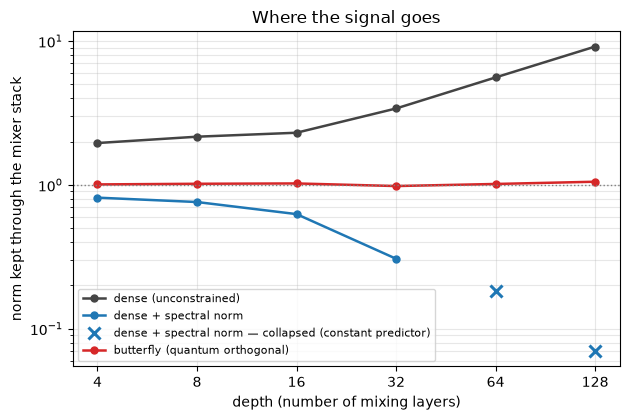

worst sigma_min over all mixers, after training:


arm,dense,dense-sn,butterfly
depth,,,
4,0.666,0.351,1.000
8,0.686,0.367,1.000
16,0.635,0.285,1.000
32,0.585,0.182,1.000
64,0.382,0.250,1.000
128,0.382,0.209,1.000


In [8]:
display(table('norm_retention', '{:.4f}'))
plot('norm_retention', 'norm kept through the mixer stack', logy=True)
plt.axhline(1.0, color='grey', ls=':', lw=1)
plt.title('Where the signal goes')
plt.tight_layout(); plt.show()

print('worst sigma_min over all mixers, after training:')
display(table('sigma_min', '{:.3f}'))

## 5.3 A small Lipschitz bound is not enough

The unconstrained `dense` model maintains high clean accuracy, but its global Lipschitz bound grows rapidly with depth:

$$
L=14.0\quad\text{at depth 4}
$$

and

$$
L\approx10^{15}\quad\text{at depth 128}.
$$

Its certified radius consequently decreases from $0.28$ to effectively zero.

Both `dense-sn` and `butterfly` maintain

$$
L=1
$$

at every depth. Up to depth 32, both therefore produce useful certified radii.

Beyond that point their behaviour separates. The butterfly model remains accurate and its certified radius stays around **1.35**. Wherever `dense-sn` collapses its computed radius is not a meaningful measure of robustness: a constant predictor has a margin and therefore a radius, but it certifies only that a constant stays constant.

This highlights an important point: **a small Lipschitz constant is necessary for a useful certificate, but it is not sufficient**. The model must also retain enough representation and classification margin to solve the task.

L_analytic (global Lipschitz upper bound):


arm,dense,dense-sn,butterfly
depth,,,
4,13.97,1,1
8,48.27,1,1
16,239.4,1,1
32,6502,1,1
64,6.365e+06,1,1
128,1.051e+15,1,1


certified L2 radius:


arm,dense,dense-sn,butterfly
depth,,,
4,0.278,1.357,1.281
8,0.107,1.320,1.305
16,0.026,1.284,1.346
32,0.002,1.100,1.367
64,0.000,0.759,1.369
128,0.000,0.482,1.352


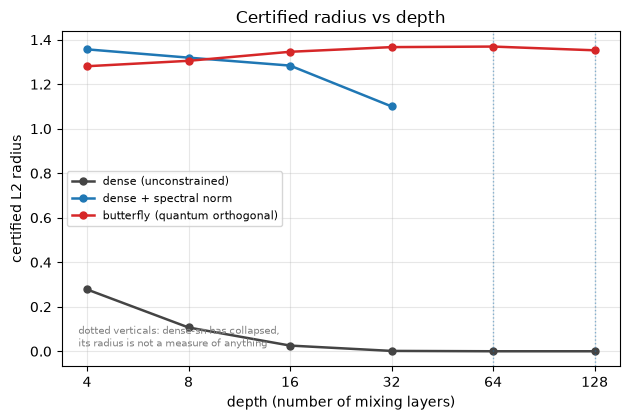

In [9]:
print('L_analytic (global Lipschitz upper bound):')
display(table('L_analytic', '{:.4g}'))
print('certified L2 radius:')
display(table('certified_radius', '{:.3f}'))

# The collapsed models are omitted from the plot rather than drawn: a constant
# predictor has a margin and therefore a "radius", but it certifies only that a
# constant stays constant.
ax = plot('certified_radius', 'certified L2 radius', show_collapsed=False)
ax.set_title('Certified radius vs depth')
ax.text(0.03, 0.06, 'dotted verticals: dense-sn has collapsed,\nits radius is not a'
        ' measure of anything', transform=ax.transAxes, fontsize=7.5, color='grey')
plt.tight_layout(); plt.show()

## 5.4 Same perturbation size, very different direction

Random and adversarial perturbations at **exactly the same $L_2$ norm**, on the deepest
models. `dense-sn` has already collapsed at depth 128, so the live comparison is `dense`
against `butterfly`.

**Random directions barely matter.** At $\epsilon = 3$, accuracy is 95.9% for `dense` and
97.0% for `butterfly`. From random noise alone the two look equally robust.

**Adversarial directions separate them completely.** At $\epsilon = 1$, PGD leaves `dense` at
5.1% and `butterfly` at 77.6% — and the certificate independently *proves* 71.5% for
`butterfly`, a lower bound sitting below the measured number.

What matters is not the size of the perturbation but its **direction**. A random direction in
$d$ dimensions aligns with the worst one by about $1/\sqrt{d}$, so random noise probes typical
behaviour and says nothing about what a Lipschitz bound controls. **This is the measurement
convention the rest of the notebook inherits**, and §8.4 finds that it holds even for
perturbations that are not $L_2$ balls at all.

The green line is the unconstrained CNN under the same two attacks: the most accurate model on
clean inputs (0.996), still there under random noise, and **below** the orthogonal model under
PGD — 0.260 against 0.480 at $\epsilon = 1.5$ — while proving nothing about any of it.

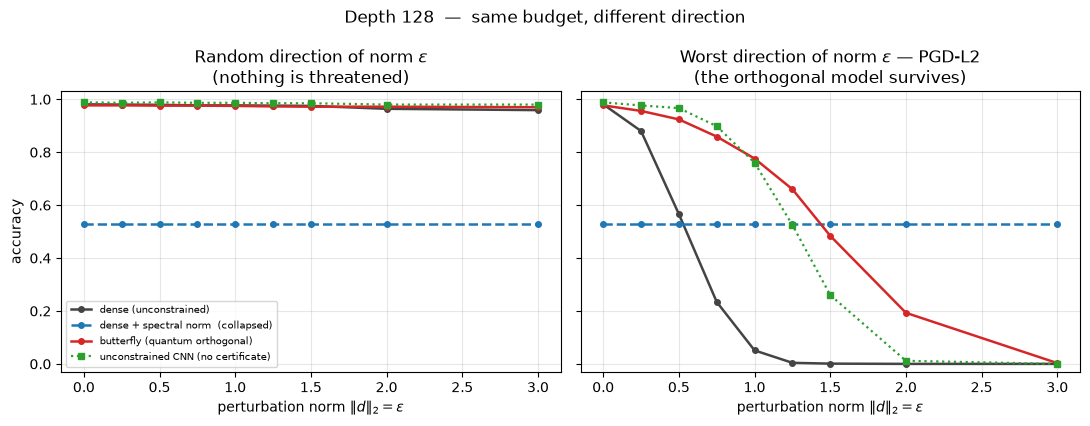

In [10]:
def perturbation_panels(depth_value):
    d = pert[pert.depth == depth_value]
    g = d.groupby(['arm', 'epsilon']).agg(
        random=('random_accuracy', 'mean'), pgd=('robust_accuracy', 'mean'),
        collapsed=('collapsed', 'any')).reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
    for arm in ARMS:
        s = g[g.arm == arm].sort_values('epsilon')
        if s.empty: continue
        broke = s['collapsed'].any()
        style = '--o' if broke else '-o'
        lab = L[arm] + ('  (collapsed)' if broke else '')
        axes[0].plot(s.epsilon, s['random'], style, color=C[arm], label=lab, ms=4, lw=1.8)
        axes[1].plot(s.epsilon, s['pgd'], style, color=C[arm], label=lab, ms=4, lw=1.8)
    # the unconstrained reference, attacked exactly the same way
    for ax, field in ((axes[0], 'random_accuracy'), (axes[1], 'robust_accuracy')):
        r = cnn_curve('mnist35', field)
        ax.plot(r.index, r.values, ':s', color=CNN_C, ms=4, lw=1.6, label=CNN_LABEL)
    axes[0].set_title('Random direction of norm $\\epsilon$\n(nothing is threatened)')
    axes[1].set_title('Worst direction of norm $\\epsilon$ — PGD-L2\n(the orthogonal model survives)')
    for ax in axes:
        ax.set_xlabel(r'perturbation norm $\|d\|_2 = \epsilon$'); ax.grid(alpha=0.3)
    axes[0].set_ylabel('accuracy'); axes[0].set_ylim(-0.03, 1.03)
    axes[0].legend(fontsize=7.5, loc='lower left')
    fig.suptitle(f'Depth {depth_value}  —  same budget, different direction')
    fig.tight_layout(); plt.show()

perturbation_panels(128)

## 5.5 Orthogonality becomes more important with depth

We finally compare PGD robust accuracy at a fixed attack radius as the network becomes deeper.

The three architectures show very different scaling behaviour.

* **`dense` becomes progressively less robust.** Robust accuracy falls from 0.105 at depth 4 to 0.001 at depth 128. The model remains accurate, but its Lipschitz bound grows rapidly with depth, making it increasingly vulnerable to worst-case perturbations.

* **`dense-sn` works well at moderate depth, then degrades and finally collapses.** It achieves robust accuracies of 0.551, 0.561, 0.545 and 0.330 up to depth 32. At depth 64 only one of its two seeds trains at all, and that surviving seed reaches 0.316 — below the butterfly's 0.491 at the same depth. At depth 128 both seeds collapse.

  Collapsed seeds are excluded from the line rather than averaged into it. A collapsed model answers the same class for every input, so it is trivially unflippable and scores the majority-class rate of 0.531 under any attack; averaging that with a working seed would report 0.42, which is neither model's behaviour.

* **`butterfly` remains trainable and becomes more robust with depth.** Robust accuracy increases from 0.333 at depth 4 to 0.484 at depth 128.

The important result is therefore not that orthogonality is always better. At shallow depth, spectral normalisation actually gives the strongest PGD robustness.

The difference appears as more constrained layers are composed. Spectral normalisation controls expansion but still allows contraction in individual directions, while the orthogonal mixer preserves every direction. As depth increases, this distinction becomes increasingly important.

In this experiment, orthogonality is the only constraint that combines a fixed Lipschitz bound with stable training and useful adversarial robustness across the full depth range.


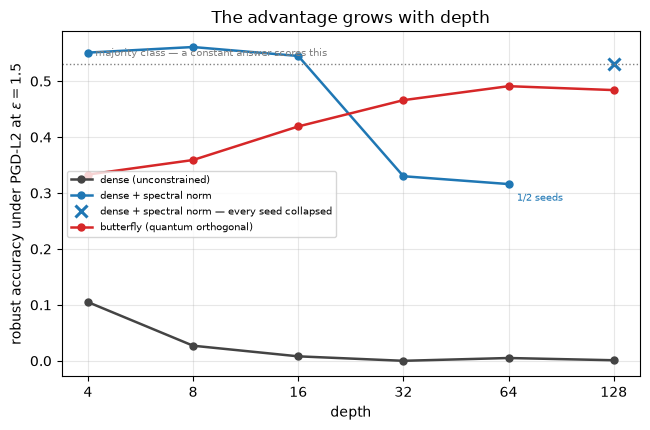

arm,dense,dense-sn,butterfly
depth,,,
4,0.105,0.551,0.333
8,0.027,0.561,0.359
16,0.008,0.545,0.419
32,0.000,0.330,0.466
64,0.005,0.423 (1/2 collapsed),0.491
128,0.001,0.530 (all collapsed),0.484


In [11]:
# Collapsed seeds are excluded from the line rather than averaged into it.
# At depth 64 one `dense-sn` seed collapsed and the other did not; averaging the
# two would report 0.42, which is neither model's behaviour. The line therefore
# shows the mean over seeds that actually learned, and a cross marks a depth
# where every seed collapsed.
fig, ax = plt.subplots(figsize=(6.6, 4.4))
for arm in ARMS:
    s = pert[(pert.arm == arm) & (pert.epsilon == 1.5)]
    live = (s[~s.collapsed].groupby('depth').robust_accuracy.mean().reset_index())
    dead = (s.groupby('depth').collapsed.all().reset_index())
    dead = dead[dead.collapsed].merge(
        s.groupby('depth').robust_accuracy.mean().reset_index(), on='depth')
    n_seeds = s.groupby('depth').seed.nunique()
    n_live = s[~s.collapsed].groupby('depth').seed.nunique()
    ax.plot(live.depth, live.robust_accuracy, '-o', color=C[arm], label=L[arm], lw=1.8, ms=5)
    for _, r in live.iterrows():                       # flag partial collapse
        if n_live.get(r.depth, 0) < n_seeds.get(r.depth, 0):
            ax.annotate(f'{int(n_live[r.depth])}/{int(n_seeds[r.depth])} seeds',
                        (r.depth, r.robust_accuracy), textcoords='offset points',
                        xytext=(6, -12), fontsize=7, color=C[arm])
    if len(dead):
        ax.plot(dead.depth, dead.robust_accuracy, 'x', color=C[arm], ms=9, mew=2.2,
                ls='none', label=L[arm] + ' — every seed collapsed')
ax.axhline(0.531, color='grey', ls=':', lw=1)
ax.text(4.2, 0.545, 'majority class — a constant answer scores this', color='grey', fontsize=7.5)
ax.set_xscale('log', base=2); ax.set_xticks(DEPTHS)
ax.set_xticklabels([str(d) for d in DEPTHS])
ax.set_xlabel('depth'); ax.set_ylabel(r'robust accuracy under PGD-L2 at $\epsilon=1.5$')
ax.set_title('The advantage grows with depth')
ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=7.5, loc='center left')
plt.tight_layout(); plt.show()

# The same numbers, per seed where the seeds disagree.
t = pert[pert.epsilon == 1.5].groupby(['arm', 'depth']).agg(
    pgd=('robust_accuracy', 'mean'),
    n_collapsed=('collapsed', 'sum'), n=('seed', 'nunique'))
t['value'] = [f'{v:.3f}' + ('  (all collapsed)' if c == n else
                            f'  ({c}/{n} collapsed)' if c else '')
              for v, c, n in zip(t.pgd, t.n_collapsed, t.n)]
t['value'].unstack(0)[list(ARMS)]

## 5.6 Buying certified radius with the loss

$r(x) = M(x)/(\sqrt{2}L)$ has two factors, and the architecture only fixes one of them.
Orthogonality pins $L=1$; the margin $M(x)$ is whatever training produces. And the radius is
**scale-invariant** — shrink a layer by $c$ and the margin shrinks by $c$ too, so moving scale
between layers buys nothing. The only way to enlarge $r$ is to train for a larger margin
relative to $L$.

`margin_loss` already has the dial: it computes cross-entropy on $z - \mathrm{offset}\cdot
\mathrm{onehot}(y)$, so the model scores well only once its margin exceeds `offset`. Sweeping
it on the bloodmnist → dermamnist adapters, 3 seeds, with $L$ untouched at 1.000025 throughout:

| offset | median $r$ | clean accuracy | JPEG q=90 covered | resize 28→20→28 covered |
|---|---|---|---|---|
| 0.5 | 0.329 ± 0.069 | 0.545 ± 0.028 | 0.633 | 0.538 |
| **1.0** (used in §5–§8) | 0.424 ± 0.040 | 0.544 ± 0.024 | 0.735 | 0.633 |
| 2.0 | 0.620 ± 0.070 | 0.545 ± 0.033 | 0.791 | 0.687 |
| **4.0** | **0.923 ± 0.025** | **0.566 ± 0.041** | **0.823** | **0.739** |
| 8.0 | 0.688 ± 0.129 | 0.526 ± 0.032 | 0.787 | 0.690 |

**The radius more than doubles at no cost in accuracy.** Per-seed at offset 4 the medians are
0.945, 0.895 and 0.928, and the rise from 0.5 to 4.0 is monotone on every seed. Clean accuracy
goes up by 2.2 points, inside its own 4-point noise — so *free*, not *better*. The default used
everywhere else in this notebook was simply too small: these models were under-trained for
margin, not sitting on an accuracy–robustness frontier.

Past the optimum the loss does degenerate as expected. At offset 8 the radius falls to 0.688
and its spread triples, because a 1-Lipschitz network's logits are inherently $O(1)$ and the
demand eventually cannot be met.

**And the adapter has far more headroom than the frozen backbone.**

| at its best offset | median $r$ | gain over offset 1.0 |
|---|---|---|
| `butterfly` | **0.923** | **2.18×** |
| `head-only` | 0.45, flat from offset 2 | 1.28× |

`head-only` trains only the final linear layer, so margin growth is capped by whatever the
frozen features already permit. `butterfly` can rotate the representation as well, and keeps
going — 2.1× ahead at the optimum against 1.2× at the default. **This is an argument for the
orthogonal adapter that does not involve the certificate at all**: it is not only that it
preserves $L$, it is that it has room to grow $M$. The OFT/BOFT line does not claim this.

Two caveats. The loss *encourages* a margin rather than enforcing one: offset 4 with $L=1$
nominally asks for a radius of $4/\sqrt{2} = 2.83$ and delivers 0.92, a threefold shortfall.
And our `offset` is a uniform handicap in logit units, where the certified-robustness
literature uses $z_j + L\epsilon\|w_y - w_j\|$ — the per-class-pair form, in which $\epsilon$
*is* the target radius in input-space $L_2$. That version is better specified: it asks for
exactly the radius you want, and weights each class pair by the term that actually appears in
the denominator of $r$. Adopting it is the obvious next change to this repo.

median_radius  radius_sd  clean_accuracy  accuracy_sd  jpeg90  resize20    L
mode      offset                                                                              
butterfly 0.5            0.3286     0.0693          0.5455       0.0279  0.6333    0.5383  1.0
          1.0            0.4243     0.0397          0.5445       0.0238  0.7347    0.6327  1.0
          2.0            0.6203     0.0699          0.5448       0.0334  0.7910    0.6867  1.0
          4.0            0.9228     0.0252          0.5661       0.0411  0.8230    0.7393  1.0
          8.0            0.6885     0.1289          0.5255       0.0318  0.7873    0.6900  1.0
head-only 0.5            0.2449     0.0296          0.5257       0.0248  0.5303    0.4167  1.0
          1.0            0.3544     0.0212          0.5540       0.0220  0.7193    0.6040  1.0
          2.0            0.4532     0.0527          0.5513       0.0171  0.7417    0.6407  1.0
          4.0            0.4356     0.0474          0.5290       0.0380  0.7277    0.6173  1.0
          8.0            0.4519     0.0255          0.5235       0.0111  0.7283    0.6463  1.0

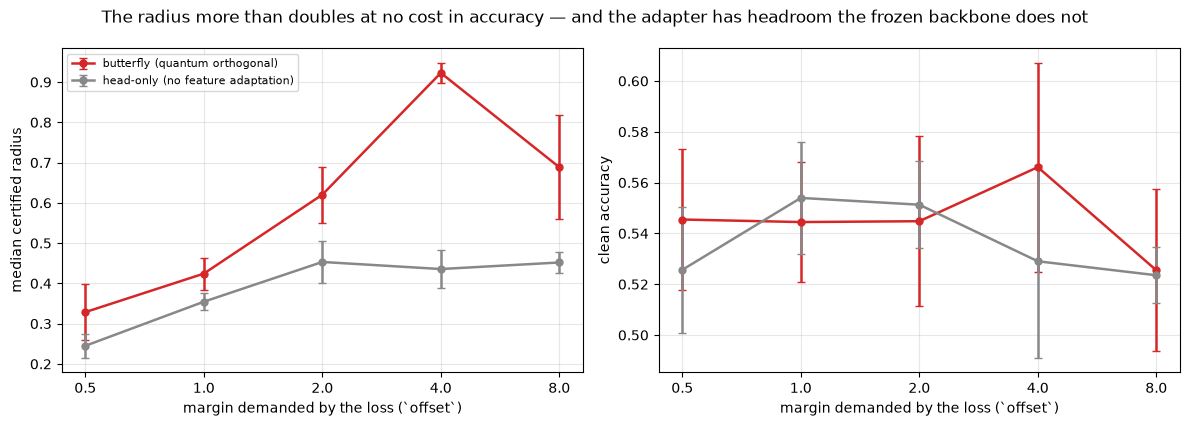

In [12]:
osw = pd.read_csv('results/offset_sweep.csv')
g = (osw.groupby(['mode', 'offset'])
     .agg(median_radius=('median_radius', 'mean'), radius_sd=('median_radius', 'std'),
          clean_accuracy=('clean_accuracy', 'mean'), accuracy_sd=('clean_accuracy', 'std'),
          jpeg90=('jpeg90', 'mean'), resize20=('resize20', 'mean'),
          L=('L_analytic', 'mean')).round(4))
display(g)

SWEEP = {'butterfly': ('#d62728', 'butterfly (quantum orthogonal)'),
         'head-only': ('#888888', 'head-only (no feature adaptation)')}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for mode, (colour, label) in SWEEP.items():
    s = osw[osw['mode'] == mode].groupby('offset')
    r, a = s.median_radius, s.clean_accuracy
    axes[0].errorbar(r.mean().index, r.mean(), yerr=r.std(), fmt='-o', color=colour,
                     capsize=3, lw=1.8, ms=5, label=label)
    axes[1].errorbar(a.mean().index, a.mean(), yerr=a.std(), fmt='-o', color=colour,
                     capsize=3, lw=1.8, ms=5, label=label)
axes[0].set_ylabel('median certified radius'); axes[1].set_ylabel('clean accuracy')
for ax in axes:
    ax.set_xscale('log', base=2); ax.set_xticks(sorted(osw.offset.unique()))
    ax.set_xticklabels([str(o) for o in sorted(osw.offset.unique())])
    ax.set_xlabel('margin demanded by the loss (`offset`)'); ax.grid(alpha=0.3, which='both')
axes[0].legend(fontsize=8)
fig.suptitle('The radius more than doubles at no cost in accuracy — and the adapter has '
             'headroom the frozen backbone does not')
fig.tight_layout(); plt.show()

# 6. Can a certificate survive fine-tuning?

So far, every model has been trained from scratch. In many realistic settings, especially with limited data, this is not practical: we would rather start from a pretrained backbone and adapt it to a new task.

The problem is that ordinary fine-tuning changes the backbone weights, and therefore can also change the singular values that determine its Lipschitz bound.

This section asks a different question:

> **Can we adapt a certified backbone while preserving the property that makes it certifiable?**

The idea is to pretrain the robust representation once, then restrict fine-tuning so that adaptation cannot increase its Lipschitz bound.

## 6.1 Preserving the certificate with an orthogonal adapter

Suppose a pretrained layer has weight matrix $W$. Instead of modifying $W$ directly, we compose it with an orthogonal transformation $R$:

$$
W' = RW,
$$

with

$$
R^\top R = I.
$$

Then

$$
(W')^\top W'
=
W^\top R^\top RW
=
W^\top W.
$$

Therefore, $W'$ has **exactly the same singular values as $W$**.

In particular,

$$
\sigma_{\max}(W')=\sigma_{\max}(W),
$$

so the layer's Lipschitz constant is unchanged.

For convolutional features, this can be implemented as an orthogonal $1\times1$ convolution acting on the output channels. In our case, $R$ is parameterised by the same butterfly circuit of Givens rotations used earlier.

This gives the quantum-inspired connection: in the unary basis, the same transformation corresponds to a circuit of RBS gates. Here it provides a trainable adapter that remains orthogonal for every value of its parameters.

This is related to orthogonal fine-tuning methods such as OFT, BOFT and qGOFT. Here, however, we use the construction specifically to test whether **certified robustness can be preserved during adaptation**.

## 6.2 Four ways to adapt the backbone

All methods use the same pretrained backbone and train a new classification head for the target task. They differ only in how much the backbone is allowed to change.

| Method      | Backbone update                                 | Trainable parameters | Certificate               |
| ----------- | ----------------------------------------------- | -------------------: | ------------------------- |
| `head-only` | Backbone frozen                                 |                2,050 | Preserved                 |
| `butterfly` | Orthogonal adapter $R$ composed with each layer |                8,194 | Preserved by construction |
| `lora`      | Low-rank additive update $W+BA$                 |               18,434 | Not guaranteed            |
| `full`      | All weights updated                             |              135,170 | Not guaranteed            |

### `head-only`

The backbone is completely frozen and only the new classifier is trained.

This is the simplest control. The pretrained representation does not change, so neither does the backbone's Lipschitz bound. The limitation is equally clear: the model can only use features that were already present in the pretrained representation.

### `full`

All backbone weights are updated.

This gives the model maximum freedom to adapt, but the original singular-value constraints are no longer preserved automatically. Even if the starting checkpoint is certified, ordinary gradient updates can move the weights away from the constrained manifold.

### `lora`

LoRA freezes $W$ and learns a low-rank additive correction:

$$
W' = W + BA,
$$

where

$$
B\in\mathbb{R}^{C\times r},
\qquad
A\in\mathbb{R}^{r\times C},
\qquad
r\ll C.
$$

Here we use $r=4$.

LoRA is parameter efficient, and with $B$ initialised to zero the model starts exactly from the pretrained function. However, the update places no constraint on the singular values of $W+BA$.

The Lipschitz bound may therefore change during training.

### `butterfly`

The butterfly adapter also starts from the pretrained function, but adapts the layer multiplicatively:

$$
W'=RW,
$$

where $R$ is an orthogonal butterfly transformation.

For $C=64$, the butterfly contains

$$
\frac{C}{2}\log_2 C = 192
$$

trainable angles.

They are initialised to zero, so initially

$$
R=I.
$$

During training, the angles change and the representation can rotate, but $R$ remains orthogonal throughout. The singular values of $W$ are therefore preserved exactly.

The important distinction is:

* LoRA changes the weights with a **low-rank additive update**.
* The butterfly changes the representation with a **spectrum-preserving orthogonal transformation**.

## 6.3 The experiment

We first train a certified backbone on MNIST 3 vs 5, with global Lipschitz bound

$$
L=1.
$$

We then adapt the same backbone to a different task: **MNIST 0 vs 8**.

Every method starts from:

* the same pretrained backbone,
* the same newly initialised classification head,
* the same initial backbone function.

For LoRA and the butterfly adapter, the update is initialised to have no effect: $BA=0$ for LoRA and $R=I$ for the butterfly.

This makes the comparison controlled. The only difference between the four arms is **how the pretrained representation is allowed to change during fine-tuning**.

The experiment therefore tests two things at once:

1. **Adaptation:** how well each method learns the new task.
2. **Certificate preservation:** whether the original Lipschitz guarantee survives that adaptation.


In [13]:
adapt = pd.read_csv(ADAPT_CSV)
print(f"backbone certified on mnist35:  L = {adapt.backbone_L.mean():.6f}")
print("unconstrained CNN on the target task (mnist08):  plain %.4f  balanced %.4f\n"
      % cnn_ref('mnist08'))

summary = (adapt.groupby('mode')
           .agg(clean_accuracy=('clean_accuracy', 'mean'),
                balanced_accuracy=('balanced_accuracy', 'mean'),
                L_analytic=('L_analytic', 'mean'),
                certified_radius=('certified_radius', 'mean'),
                trainable_params=('trainable_params', 'first'))
           .loc[list(MODES)])
summary

backbone certified on mnist35:  L = 1.000000
unconstrained CNN on the target task (mnist08):  plain 0.9992  balanced 0.9992



,clean_accuracy,balanced_accuracy,L_analytic,certified_radius,trainable_params
mode,,,,,
head-only,0.990532,0.990528,1.000010,1.116023,2050
butterfly,0.993603,0.993594,1.000017,1.760165,8194
lora,0.991812,0.991799,1529.332250,0.003200,18434
full,0.991300,0.991283,1825.451970,0.004237,135170


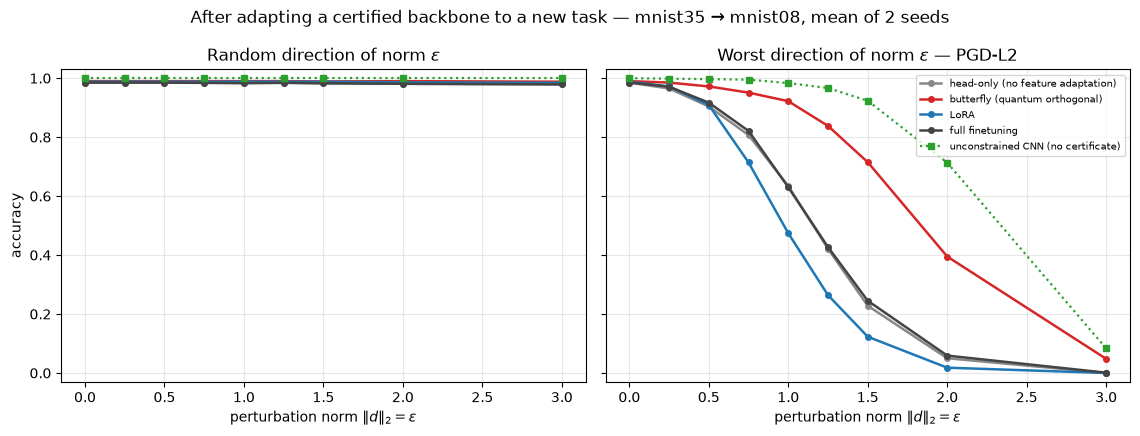

plain and balanced accuracy, and robust accuracy under PGD-L2:


mode,head-only,butterfly,lora,full
epsilon,,,,
0.00,0.985,0.990,0.988,0.985
0.25,0.965,0.985,0.972,0.971
0.50,0.904,0.972,0.909,0.917
0.75,0.807,0.951,0.714,0.821
1.00,0.634,0.922,0.474,0.630
1.25,0.421,0.838,0.264,0.427
1.50,0.228,0.715,0.123,0.245
2.00,0.050,0.395,0.018,0.059
3.00,0.000,0.048,0.000,0.001


In [14]:
CM = {'head-only': '#888888', 'butterfly': '#d62728', 'lora': '#1f77b4', 'full': '#444444'}
LM = {'head-only': 'head-only (no feature adaptation)', 'butterfly': 'butterfly (quantum orthogonal)',
      'lora': 'LoRA', 'full': 'full finetuning'}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
for ax, field, title in ((axes[0], 'random_accuracy',
                          'Random direction of norm $\\epsilon$'),
                         (axes[1], 'robust_accuracy',
                          'Worst direction of norm $\\epsilon$ — PGD-L2')):
    for mode in MODES:
        s = adapt[adapt['mode'] == mode].groupby('epsilon')[field].mean()
        ax.plot(s.index, s.values, '-o', color=CM[mode], label=LM[mode], lw=1.8, ms=4)
    r = cnn_curve('mnist08', field)          # same attacks, no certificate
    ax.plot(r.index, r.values, ':s', color=CNN_C, ms=4, lw=1.6, label=CNN_LABEL)
    ax.set_xlabel(r'perturbation norm $\|d\|_2 = \epsilon$')
    ax.set_title(title); ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy'); axes[0].set_ylim(-0.03, 1.03)
axes[1].legend(fontsize=7.5, loc='upper right')
fig.suptitle('After adapting a certified backbone to a new task — mnist35 → mnist08, '
             'mean of 2 seeds')
fig.tight_layout(); plt.show()

print('plain and balanced accuracy, and robust accuracy under PGD-L2:')
display(adapt.groupby(['mode', 'epsilon']).robust_accuracy.mean()
        .unstack(0)[list(MODES)].round(3))

## 6.4 Fine-tuning results

|                                 | `head-only` | `butterfly` | `lora` |  `full` |
| ------------------------------- | ----------: | ----------: | -----: | ------: |
| clean accuracy                  |      0.9905 |  **0.9936** | 0.9918 |  0.9913 |
| $L_{\mathrm{analytic}}$         |       1.000 |   **1.000** |   1529 |    1825 |
| certified radius                |       1.116 |   **1.760** |  0.003 |   0.004 |
| robust accuracy at $\epsilon=1$ |       0.634 |   **0.922** |  0.474 |   0.630 |
| robust accuracy at $\epsilon=2$ |       0.050 |   **0.395** |  0.018 |   0.059 |
| trainable parameters            |       2,050 |       8,194 | 18,434 | 135,170 |

The certificate behaves exactly as the algebra predicts. `butterfly` holds `L = 1.000000`;
`lora` and `full` blow it up by three orders of magnitude, and their certified radius
collapses from ~1.8 to ~0.004 — a **400×** loss.

Note that `butterfly` is not merely keeping up: it has the **highest clean accuracy of the
four**, and a *larger* certified radius than `head-only`. So the adapter is genuinely
adapting, not just declining to move. That rules out the trivial explanation.

All four methods reach essentially the same clean accuracy; the difference is all in robustness.

The butterfly adapter preserves $L=1$ exactly while increasing the certified radius from 1.116 to 1.760. LoRA and full fine-tuning reach similar clean accuracy, but their Lipschitz bounds grow by three orders of magnitude, leaving almost no useful certified radius.

The same pattern appears under PGD. At $\epsilon=1$, the butterfly retains **92.2%** robust accuracy, and at $\epsilon=2$ it retains **39.5%**, clearly above the other adaptation methods.

It also uses fewer trainable parameters than LoRA and far fewer than full fine-tuning.

### The reference line is uncomfortable here, and worth reading carefully

The unconstrained CNN in the figure above is, on this task, **more robust than every
adapter**: 0.983 at $\epsilon=1$ and 0.713 at $\epsilon=2$, against the butterfly adapter's
0.922 and 0.395. That is a real measurement and it should not be hidden.

Two things make it less of a contradiction than it looks:

1. **`mnist08` is 0 versus 8.** The two classes are about as separable as two classes get, so
   an unconstrained model lands in a wide, flat basin with enormous margins. This is the
   easiest possible case for empirical robustness, and §7 — where the task is genuinely hard
   — reverses the ordering completely: there the same CNN falls to 0.012 at $\epsilon=1$
   while the orthogonal model holds 0.265.

2. **The two numbers are not the same kind of number.** The adapter's 0.395 is a *lower
   bound*: PGD found no perturbation of norm 2 that flips those images, and the certificate
   independently proves a radius of 1.76 within which nothing can. The CNN's 0.713 is an
   *upper bound* on its true robustness — it is what a 50-step, 2-restart PGD happened not to
   break, and a stronger attack can only lower it. An unconstrained model can be empirically
   robust and still prove nothing; that gap is the entire history of broken empirical
   defences.

So the honest reading is: on an easy binary task, constraining the model costs empirical
robustness and buys a proof. Whether the proof is worth it depends on whether you need a
guarantee or an average.

## 6.5 What this shows

The key result is that **feature adaptation and certificate preservation can coexist**.

A frozen backbone keeps its certificate but cannot adapt its representation. LoRA and ordinary fine-tuning can adapt it, but do not preserve the singular-value constraints. The orthogonal adapter does both:

$$
\text{adapt the representation}
\quad+\quad
\text{preserve the spectrum}.
$$

In this experiment, that is enough to improve both certified and empirical robustness without sacrificing clean accuracy.

This suggests a practical route for transfer learning: pretrain a certified backbone once, then adapt it to smaller downstream datasets using spectrum-preserving adapters.

## 6.6 Limitations

This result is still a proof of concept.

* **Scale:** the experiment is MNIST-to-MNIST. Larger domain shifts may require more adaptation capacity.
* **Backbone quality:** certified pretrained models are typically weaker than standard pretrained models, which may limit downstream performance.
* **Certificate meaning:** an $L_2$ certificate controls worst-case perturbations, not realistic corruptions, dataset shift, or patient-level generalisation.

The next question is therefore whether the same mechanism remains useful with realistic pretrained backbones and larger domain shifts.


# 7. Does any of this survive on a clinical dataset?

Everything so far is MNIST: greyscale, two balanced classes, a task where every model
reaches 98%. This section repeats **both** experiments on
[DermaMNIST](https://medmnist.com/) — the MedMNIST v2 release of the HAM10000 dermatoscopic
archive — which is much closer to the setting we actually care about.

| | MNIST (§5–6) | DermaMNIST |
|---|---|---|
| input | 28×28 greyscale | 28×28 **RGB** |
| classes | 2 | **7** skin-lesion types |
| training images | 11,552 | **7,007** |
| class balance | 53 / 47 | **67% melanocytic nevi**; the rarest class is 80 images (1.1%) |
| a constant predictor scores | 0.531 | **0.669** |

The imbalance is the point, and it mirrors the clinical setting: a model that answers
"nevus" to everything scores 67%, which looks respectable and is useless.

## 7.1 What had to change, and why

Four things, each forced by the dataset rather than chosen:

1. **Width.** The architecture needs `channels = lift · 4³` with `lift ≥ in_channels`, and
   the butterfly circuit needs a power of two, so RGB forces `lift = 4` and **C = 256**
   rather than 64. The lift is `torch.eye(4, 3)` — orthonormal columns, hence an isometry,
   so it still contributes exactly 1 to the bound.

2. **Class-weighted loss.** Without it the loss is dominated by nevi and *even the
   unconstrained model* barely beats chance: a pilot sweep left every arm at 0.17–0.26
   balanced accuracy against 0.143 chance. With inverse-frequency weights the same
   unconstrained model reaches 0.54. Comparing arms is only meaningful once the task is
   being learned at all.

3. **Balanced accuracy** — mean per-class recall — as the headline number. Plain accuracy
   is uninterpretable at a 67/1 split, and because the weighted loss deliberately buys
   minority recall with majority accuracy, a *well-trained* model here scores **below** the
   0.669 majority rate on plain accuracy.

4. **A direct test for collapse.** Because of (3), the old "accuracy ≤ majority rate" test
   would have labelled good models as collapsed. `collapsed` now means what it says: the
   model emits **one class for every input**. This mattered — some `dense-sn` seeds
   collapsed onto a *minority* class and scored 0.03 plain accuracy, which the old test
   would have read as merely bad rather than degenerate.

30 epochs rather than 10; architecture, seeds, attacks and measurement are otherwise
unchanged. Results go to `results/derma_*.csv`, leaving the MNIST results untouched.

In [15]:
if RUN:
    # The section 7 replication. ~4 h on an M-series GPU: C = 256 rather than 64,
    # and 30 epochs rather than 10. Writes to its own CSVs.
    from experiments import run_adaptation_grid, run_grid
    for path in (DERMA_DEPTH_CSV, DERMA_PERTURBATION_CSV, DERMA_ADAPT_CSV):
        if os.path.exists(path):
            os.remove(path)
    run_grid(dataset='dermamnist', depths=DERMA_DEPTHS, seeds=SEEDS,
             epochs=DERMA_EPOCHS, class_weights=True,
             depth_csv=DERMA_DEPTH_CSV, pert_csv=DERMA_PERTURBATION_CSV)
    run_adaptation_grid('bloodmnist', 'dermamnist', seeds=SEEDS,
                        epochs=DERMA_EPOCHS, class_weights=True,
                        adapt_csv=DERMA_ADAPT_CSV)

dd = pd.read_csv(DERMA_DEPTH_CSV)
dp = pd.read_csv(DERMA_PERTURBATION_CSV)
da = pd.read_csv(DERMA_ADAPT_CSV)
CHANCE, MAJORITY = 1 / 7, 0.669
DERMA_REF = cnn_ref('dermamnist', class_weights=True)   # the matched recipe

print(f'{len(dd)} trained models, {len(dp)} perturbation measurements')
print(f'chance balanced accuracy {CHANCE:.3f}; a constant "nevus" answer scores '
      f'{MAJORITY:.3f} on plain accuracy')
print('unconstrained CNN, same recipe:  plain %.4f  balanced %.4f' % DERMA_REF)
assert dd['bound_respected'].all(), 'a Lipschitz bound was violated'

def dtable(column, fmt='{:.4f}'):
    t = dd.groupby(['arm', 'depth'])[column].mean().unstack(0)[list(ARMS)]
    return t.map(lambda v: fmt.format(v) if pd.notna(v) else '--')

print('\nplain accuracy:');    display(dtable('clean_accuracy'))
print('balanced accuracy:');   display(dtable('balanced_accuracy'))
print('seeds that collapsed to a constant predictor, out of 2:')
display(dd.groupby(['arm', 'depth']).collapsed.sum().unstack(0)[list(ARMS)])

24 trained models, 216 perturbation measurements
chance balanced accuracy 0.143; a constant "nevus" answer scores 0.669 on plain accuracy
unconstrained CNN, same recipe:  plain 0.6170  balanced 0.5660

plain accuracy:


arm,dense,dense-sn,butterfly
depth,,,
4,0.5566,0.4768,0.5065
16,0.4496,0.3893,0.5294
32,0.4030,0.3601,0.5267
64,0.2733,0.3509,0.5471


balanced accuracy:


arm,dense,dense-sn,butterfly
depth,,,
4,0.4942,0.4556,0.4874
16,0.2917,0.1429,0.4950
32,0.3093,0.1429,0.4728
64,0.1987,0.1429,0.4055


seeds that collapsed to a constant predictor, out of 2:


arm,dense,dense-sn,butterfly
depth,,,
4,0,0,0
16,0,2,0
32,0,2,0
64,0,2,0


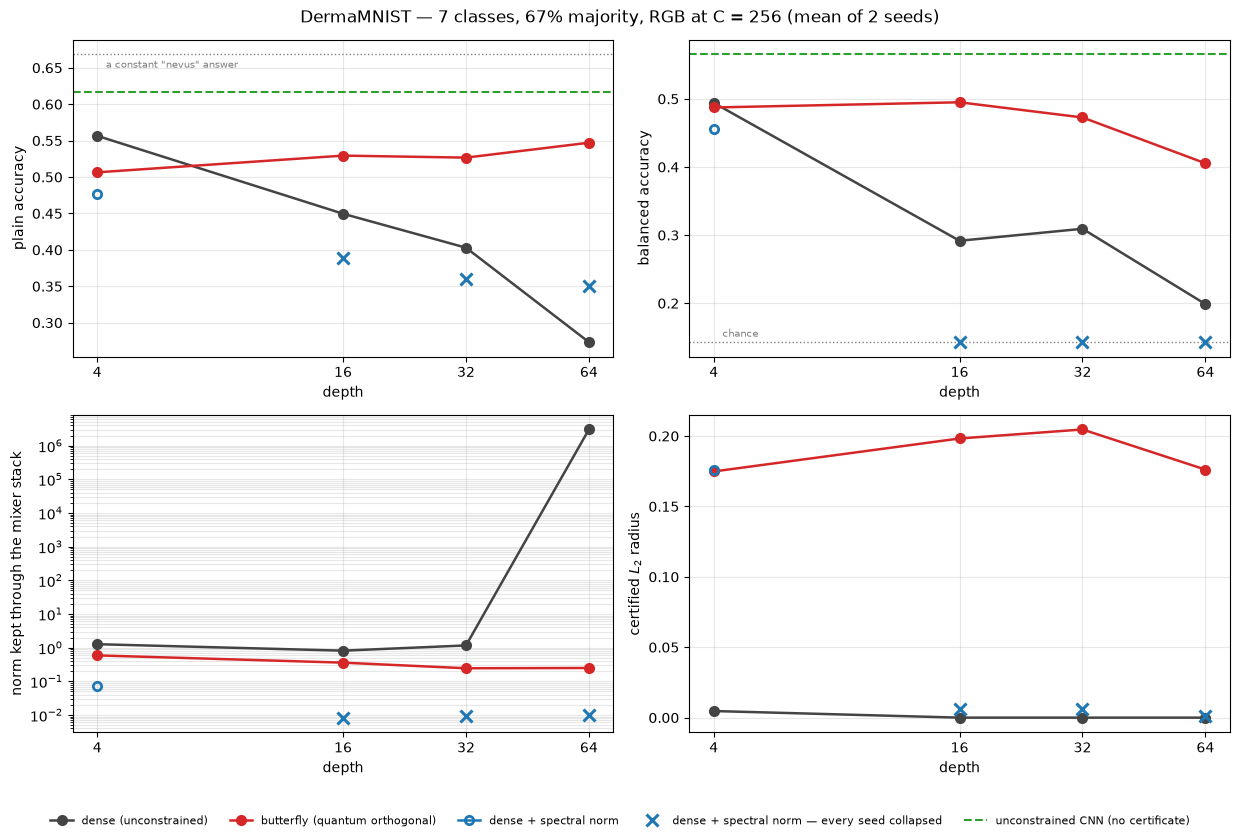

L_analytic:


arm,dense,dense-sn,butterfly
depth,,,
4,83.4,1,1
16,2.55e+06,1,1
32,1.15e+15,1,1
64,4.9e+39,1,1


In [16]:
# Same convention as section 5: a depth where every seed collapsed is drawn as an
# isolated cross, never joined to the live part of the line. `dense-sn` therefore
# appears as a single point at depth 4 -- it has no live point to join it to.
# It is drawn last, with a hollow marker, because at depth 4 its certified radius
# (0.1759) sits almost exactly on top of butterfly's (0.1748).
Z = {'dense': 2, 'butterfly': 3, 'dense-sn': 4}
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.4))
panels = [('clean_accuracy', 'plain accuracy', False, DERMA_REF[0]),
          ('balanced_accuracy', 'balanced accuracy', False, DERMA_REF[1]),
          ('norm_retention', 'norm kept through the mixer stack', True, None),
          ('certified_radius', 'certified $L_2$ radius', False, None)]
for ax, (col, ylabel, logy, ref) in zip(axes.ravel(), panels):
    for arm in sorted(ARMS, key=Z.get):
        s = (dd[dd.arm == arm].groupby('depth')
             .agg(v=(col, 'mean'), dead=('collapsed', 'all')).reset_index())
        live, dead = s[~s.dead], s[s.dead]
        ax.plot(live.depth, live.v, '-o', color=C[arm], label=L[arm], lw=1.8, ms=6,
                zorder=Z[arm], mfc='none' if arm == 'dense-sn' else C[arm], mew=2)
        if len(dead):
            ax.plot(dead.depth, dead.v, 'x', color=C[arm], ms=9, mew=2.2, ls='none',
                    zorder=Z[arm], label=L[arm] + ' — every seed collapsed')
    if ref is not None:
        cnn_line(ax, ref)
    ax.set_xscale('log', base=2); ax.set_xticks([4, 16, 32, 64])
    ax.set_xticklabels(['4', '16', '32', '64'])
    if logy: ax.set_yscale('log')
    ax.set_xlabel('depth'); ax.set_ylabel(ylabel); ax.grid(alpha=0.3, which='both')

axes[0, 0].axhline(MAJORITY, color='grey', ls=':', lw=1)
axes[0, 0].text(4.2, MAJORITY - 0.008, 'a constant "nevus" answer', color='grey',
                fontsize=7.5, va='top')
axes[0, 1].axhline(CHANCE, color='grey', ls=':', lw=1)
axes[0, 1].text(4.2, CHANCE + 0.008, 'chance', color='grey', fontsize=7.5)

h, lab = axes[0, 1].get_legend_handles_labels()
fig.legend(h, lab, loc='lower center', ncol=5, fontsize=8, frameon=False)
fig.suptitle('DermaMNIST — 7 classes, 67% majority, RGB at C = 256 (mean of 2 seeds)')
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

print('L_analytic:'); display(dtable('L_analytic', '{:.3g}'))

## 7.2 Depth: the same separation, four times sooner

| depth | `dense` | `dense-sn` | `butterfly` |
|---|---|---|---|
| 4 | 0.494 | 0.456 | 0.487 |
| 16 | 0.292 | **0.143** — both seeds collapsed | **0.495** |
| 32 | 0.309 | **0.143** — both seeds collapsed | **0.473** |
| 64 | 0.199 | **0.143** — both seeds collapsed | **0.406** |

Balanced accuracy, mean of 2 seeds; chance is 0.143. The figure shows plain accuracy alongside it, and both panels carry the unconstrained CNN as a dashed green line — under the same class-weighted recipe it reaches 0.617 plain and 0.566 balanced, so it is above every arm on both, at every depth.

At **depth 4 there is no story**: all three arms land within 4 points of each other, and
`dense-sn` and `butterfly` have essentially the same certified radius (0.176 against 0.175).
A shallow spectrally normalised network is a perfectly good certified model. Everything that
follows is about what happens when you go deeper.

* **`dense-sn` collapses at depth 16** — both seeds, and it stays collapsed at 32 and 64.
  On MNIST it survived depth 32 intact and was still half-trainable at 64. Its norm retention
  here is **0.008** at depth 16, against 0.63 at the same depth on MNIST: wider layers and a
  harder task make the contraction far more severe, and the model destroys 99% of the signal
  before reaching the head.
* **`dense` stays trainable but degrades**, 0.494 → 0.199, and its Lipschitz constant runs
  away to **4.9 × 10³⁹**. Its norm retention at depth 64 is 3 × 10⁶: it is not contracting
  but *exploding*, which is the other way to have no usable certificate.
* **`butterfly` is the only arm still learning at every depth** (0.41–0.50), with `L = 1`
  exactly and a certified radius of 0.17–0.20 throughout.

So on a harder, imbalanced, colour dataset the orthogonal parameterisation is not a marginal
improvement past depth 16 — it is the only one of the three that yields a working model with
a certificate at all.

**One number to read carefully.** `butterfly`'s norm retention is 0.25–0.59 here, not ≈1 as
on MNIST. The mixers are still exact isometries; `norm_retention` measures the *whole* stack,
including the spectrally normalised depthwise convolutions, the convex residuals and the
biases, all of which are non-expansive by construction and on this dataset genuinely do
contract. The certificate is unaffected — `L = 1` already allows for exactly this — but the
retention number is no longer a clean read of the mixers alone.

## 7.3 Robustness before any fine-tuning

Section 7.2 is about whether the models train at all. This is the attack measurement of
§5.4–5.5, run on the same from-scratch DermaMNIST models: 300 test images, a random
direction and a PGD-L2 attack at each $\epsilon$, plus the fraction of images whose margin
is large enough that the Lipschitz bound *proves* no perturbation of that size can flip them.

| robust accuracy, PGD-L2 at $\epsilon=1$ | `dense` | `dense-sn` | `butterfly` |
|---|---|---|---|
| depth 4 | 0.010 | **0.220** | 0.117 |
| depth 16 | 0.078 | *0.390 — collapsed* | 0.137 |
| depth 32 | 0.057 | *0.357 — collapsed* | 0.152 |
| depth 64 | 0.000 | *0.355 — collapsed* | **0.265** |

Three things, and the first is not the one we were looking for:

* **At depth 4 spectral normalisation is the most robust arm, by a factor of two.** This is
  real and it is not an accident: `dense-sn` retains 7% of the signal norm, and heavy
  contraction *is* a defence — it discards the adversarial component along with everything
  else. At depth 4 the model can still afford that, and it keeps essentially the same clean
  accuracy as the other two (0.456 vs 0.487 balanced). Orthogonality buys nothing here.
  What kills `dense-sn` is not the contraction, it is the contraction *compounding* — by
  depth 16 it is down to 0.8% and has nothing left to classify with.

* **Past depth 16, `dense-sn`'s flat line is the collapsed constant predictor of §5.5** —
  unflippable because there is nothing to flip, which is why those points are crosses.

* **`butterfly`'s robust accuracy rises with depth** — 0.117, 0.137, 0.152, 0.265 at
  $\epsilon=1$ — while `dense` falls to zero. This is the §5.5 result reproduced on clinical
  data: the deeper the network, the more the orthogonal parameterisation is worth. (At
  $\epsilon=1.5$ the trend is noisier, 0.035 → 0.023 → 0.045 → 0.130; two seeds is not enough
  to call the shape of the curve, only its direction.)

The certified numbers are cleaner than the attack numbers, because they do not depend on how
hard the attacker tried. At depth 64, `butterfly` **proves** that 28.3% of test images cannot
be flipped by any perturbation of norm 0.5. `dense` proves nothing at any depth ($L \approx
10^{39}$), and `dense-sn` proves nothing past depth 4 — its bound is 1, but its margins have
been contracted to nothing.

And §5.4's lesson holds unchanged on clinical data: random noise separates none of this —
every non-collapsed model loses under 10 points at $\epsilon=3$, six times the budget PGD
needs to destroy `dense`.

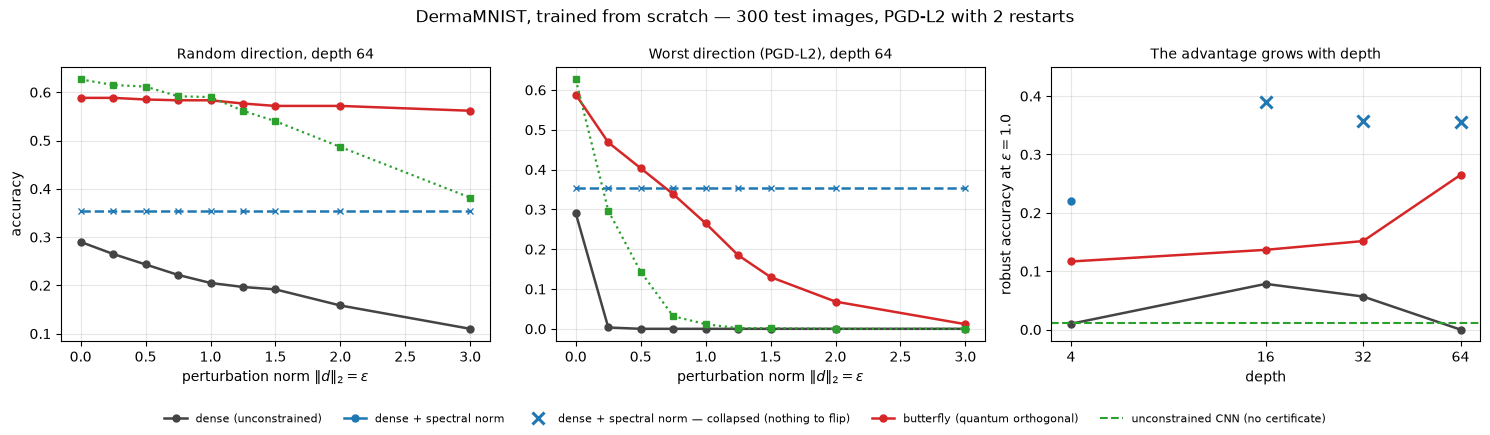

robust accuracy under PGD-L2 at epsilon = 1.0:


arm,dense,dense-sn,butterfly
depth,,,
4,0.010,0.220,0.117
16,0.078,0.390,0.137
32,0.057,0.357,0.152
64,0.000,0.355,0.265


certified accuracy at epsilon = 0.5 (proved, not measured):


arm,dense,dense-sn,butterfly
depth,,,
4,0.0,0.215,0.202
16,0.0,0.000,0.257
32,0.0,0.000,0.253
64,0.0,0.000,0.283


In [17]:
EPS_MAIN = 1.0
CNN_KW = dict(class_weights=True)          # the recipe section 7 uses
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

for ax, field, title in ((axes[0], 'random_accuracy', 'Random direction, depth 64'),
                         (axes[1], 'robust_accuracy', 'Worst direction (PGD-L2), depth 64')):
    for arm in ARMS:
        s = dp[(dp.arm == arm) & (dp.depth == 64)]
        dead = bool(s.collapsed.all())
        ax.plot(s.groupby('epsilon')[field].mean(), '--x' if dead else '-o',
                color=C[arm], lw=1.8, ms=5,
                label=L[arm] + (' — collapsed' if dead else ''))
    r = cnn_curve('dermamnist', field, **CNN_KW)
    ax.plot(r.index, r.values, ':s', color=CNN_C, ms=4, lw=1.6, label=CNN_LABEL)
    ax.set_xlabel(r'perturbation norm $\|d\|_2 = \epsilon$'); ax.grid(alpha=0.3)
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel('accuracy')

# How the advantage moves with depth, at a single perturbation size.
ax = axes[2]
for arm in ARMS:
    s = dp[(dp.arm == arm) & (dp.epsilon == EPS_MAIN)]
    g = s.groupby('depth').agg(v=('robust_accuracy', 'mean'), dead=('collapsed', 'all'))
    live, dead = g[~g.dead], g[g.dead]
    ax.plot(live.index, live.v, '-o', color=C[arm], lw=1.8, ms=5, label=L[arm])
    if len(dead):
        ax.plot(dead.index, dead.v, 'x', color=C[arm], ms=9, mew=2.2, ls='none',
                label=L[arm] + ' — collapsed (nothing to flip)')
cnn_line(ax, float(cnn_curve('dermamnist', 'robust_accuracy', **CNN_KW).loc[EPS_MAIN]))
ax.set_xscale('log', base=2); ax.set_xticks([4, 16, 32, 64])
ax.set_xticklabels(['4', '16', '32', '64'])
ax.set_xlabel('depth'); ax.set_ylabel(f'robust accuracy at $\\epsilon={EPS_MAIN}$')
ax.set_title('The advantage grows with depth', fontsize=10)
ax.grid(alpha=0.3, which='both'); ax.set_ylim(-0.02, 0.45)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=5,
           fontsize=8, frameon=False)
fig.suptitle('DermaMNIST, trained from scratch — 300 test images, PGD-L2 with 2 restarts')
fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

print(f'robust accuracy under PGD-L2 at epsilon = {EPS_MAIN}:')
display(dp[dp.epsilon == EPS_MAIN].groupby(['arm', 'depth'])
        .robust_accuracy.mean().unstack(0)[list(ARMS)].round(3))
print('certified accuracy at epsilon = 0.5 (proved, not measured):')
display(dp[dp.epsilon == 0.5].groupby(['arm', 'depth'])
        .certified_accuracy.mean().unstack(0)[list(ARMS)].round(3))

---
## 7.4 Fine-tuning: BloodMNIST → DermaMNIST

In §6 the backbone was certified on one MNIST pair and adapted to another. Here the transfer
is a real one, and it is the shape the clinical use case would actually take: pretrain on a
**larger, balanced** dataset, then adapt to a **smaller, badly imbalanced** one.

* **source:** BloodMNIST — 11,959 images, 8 classes, roughly balanced (19.5% majority)
* **target:** DermaMNIST — 7,007 images, 7 classes, 67% majority

The backbone is `butterfly`, depth 32, C = 256, certified at `L = 1.000000`. The four
adapters are unchanged from §6.2.

backbone certified on bloodmnist:  L = 1.000000
unconstrained CNN on the target task, same recipe:  plain 0.6170  balanced 0.5660



,clean_accuracy,balanced_accuracy,L_analytic,certified_radius,trainable_params
mode,,,,,
head-only,0.4938,0.5056,1.000000e+00,0.1808,28679
butterfly,0.5359,0.5152,1.000000e+00,0.2142,61447
lora,0.5678,0.5477,3.835504e+07,0.0000,94215
full,0.1429,0.2652,1.394246e+19,0.0000,2134023


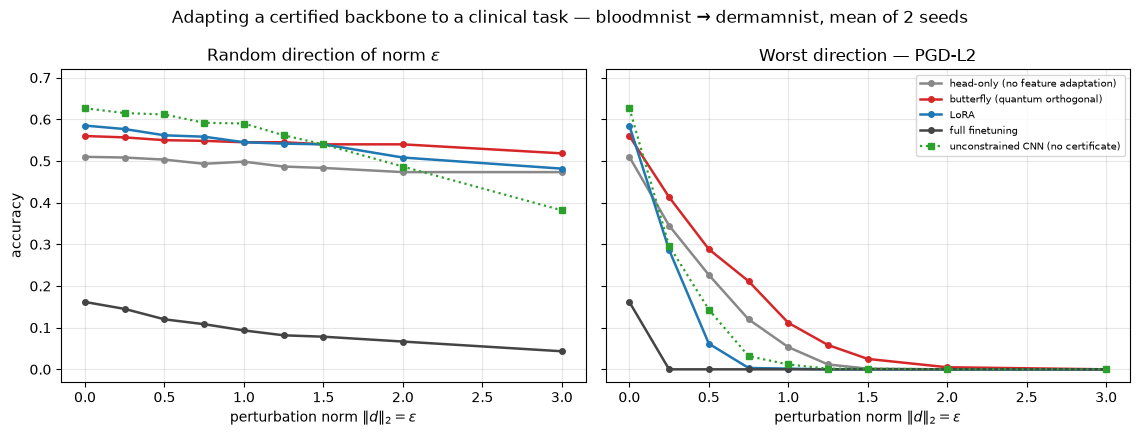

mode,head-only,butterfly,lora,full
epsilon,,,,
0.00,0.510,0.560,0.585,0.162
0.25,0.345,0.413,0.287,0.000
0.50,0.227,0.288,0.062,0.000
0.75,0.120,0.212,0.003,0.000
1.00,0.053,0.112,0.002,0.000
1.25,0.012,0.058,0.000,0.000
1.50,0.002,0.025,0.000,0.000
2.00,0.000,0.005,0.000,0.000
3.00,0.000,0.000,0.000,0.000


In [18]:
print(f'backbone certified on bloodmnist:  L = {da.backbone_L.mean():.6f}')
print('unconstrained CNN on the target task, same recipe:  '
      'plain %.4f  balanced %.4f\n' % DERMA_REF)
display(da.groupby('mode')
        .agg(clean_accuracy=('clean_accuracy', 'mean'),
             balanced_accuracy=('balanced_accuracy', 'mean'),
             L_analytic=('L_analytic', 'mean'),
             certified_radius=('certified_radius', 'mean'),
             trainable_params=('trainable_params', 'first'))
        .loc[list(MODES)].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
for ax, field, title in ((axes[0], 'random_accuracy', 'Random direction of norm $\\epsilon$'),
                         (axes[1], 'robust_accuracy', 'Worst direction — PGD-L2')):
    for mode in MODES:
        s = da[da['mode'] == mode].groupby('epsilon')[field].mean()
        ax.plot(s.index, s.values, '-o', color=CM[mode], label=LM[mode], lw=1.8, ms=4)
    r = cnn_curve('dermamnist', field, class_weights=True)
    ax.plot(r.index, r.values, ':s', color=CNN_C, ms=4, lw=1.6, label=CNN_LABEL)
    ax.set_xlabel(r'perturbation norm $\|d\|_2 = \epsilon$')
    ax.set_title(title); ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy'); axes[0].set_ylim(-0.03, 0.72)
axes[1].legend(fontsize=7.5)
fig.suptitle('Adapting a certified backbone to a clinical task — bloodmnist → dermamnist, '
             'mean of 2 seeds')
fig.tight_layout(); plt.show()

da.groupby(['mode', 'epsilon']).robust_accuracy.mean().unstack(0)[list(MODES)].round(3)

## 7.5 What the clinical replication shows — including one thing MNIST hid
The certificate result of §6 transfers intact: **the orthogonal adapter holds `L = 1.000000`
exactly while LoRA and full fine-tuning inflate it by seven and nineteen orders of
magnitude.** The algebra does not care what the data looks like — $(RW)^\top(RW) = W^\top W$
holds on dermatoscopy as it does on digits — and the attack curves in the figure above follow it:
`butterfly` is the most robust arm at every $\epsilon$ and beats `head-only` on every axis,
so it is genuinely adapting rather than declining to move.

**But something is different here, and it is the more interesting result.** On MNIST the
orthogonal adapter had the *best* clean accuracy of the four; there was no trade-off to make.
On DermaMNIST **LoRA wins on accuracy by 3.3 balanced points** (0.548 against 0.515) — and
gives up the entire certificate to do it. Once the task is hard enough, the extra freedom of
an unconstrained low-rank update buys real accuracy. That trade was invisible on MNIST, and
it is exactly the number a clinical deployment would have to weigh: about three points of
balanced accuracy against a radius-0.21 guarantee and four times the robust accuracy under
attack.

`full` fine-tuning is the outlier: 2.1M trainable parameters over 7,007 images at depth 32
does not train usefully at all (0.143 clean, 0.265 balanced — it has stopped predicting the
majority class without learning anything better). That is its own argument for
parameter-efficient adaptation on small clinical datasets, independent of certificates.

**What the constraint costs, measured.** An ordinary unconstrained CNN trained on the same
data under the best recipe we found reaches 0.621 balanced accuracy. Our backbone with the
*mixer left unconstrained* reaches 0.605 — so the architecture itself is nearly free — and the
same backbone at $L = 1$ reaches 0.516. **Roughly nine balanced-accuracy points are the price
of the certificate**, not of the design around it. Trained the ordinary way, without class
weights, `butterfly` reaches 0.706 *plain* accuracy against a published ResNet-18's 0.735 — but
gets there by never predicting two of the seven classes, which is why §7 reports balanced
accuracy throughout. Full grid in `results/baseline.csv`.

---
# 8. How much noise does it actually take?

Everything so far reports **robust accuracy at a fixed $\epsilon$**: what fraction of images
survive a given budget. That is an aggregate, and it hides the question you actually want
answered — *how much noise does it take to break this model?*

So this section measures that directly, per image, and compares it with what the certificate
proves.

## 8.1 Three numbers, not one

For one test image $x$ there are three different quantities, and they are routinely confused:

| | what it is | how we get it |
|---|---|---|
| $r(x)$ — **certified radius** | the **proven** safe zone. No perturbation smaller than this *can* flip the label. A theorem. | $\mathrm{margin}(x) / (\sqrt{2}L)$ — arithmetic, no attack |
| $d^*(x)$ — **true breaking point** | the actual smallest perturbation that flips it | not computable exactly (NP-hard) |
| $\epsilon^*(x)$ — **measured breaking point** | the smallest perturbation *our attack could find* that flips it | a bisection search, below |

They are always ordered: $r(x) \le d^*(x) \le \epsilon^*(x)$.

**Finding $\epsilon^*$.** `min_adversarial_distance` brackets by doubling the budget until the
attack succeeds, then bisects, keeping the smallest budget that ever worked. Images the model
already gets wrong are recorded as 0; images that no budget up to $\epsilon_{\max}=8$ could
break are recorded as **censored** rather than silently clipped — which matters, because a
collapsed constant predictor is unbreakable for a reason that has nothing to do with
robustness.

**Note on $r$.** Sections 5 and 7 report the median certified radius over *all* evaluated
images, including the misclassified ones whose margins are negative. Here the median is over
correctly classified images only, because $\epsilon^*$ is undefined for the rest. On MNIST the
two agree (1.352 vs 1.346); on DermaMNIST, where 45% of images are wrong, they cannot.

**Attacking *at* $r(x)$ would be pointless.** Below the certified radius a flip is
mathematically impossible, so the attack failing tells you nothing about the model — only that
our code is right. That check runs on every image anyway (`n_violations`), and it has never
fired. The information is just **above** $r(x)$.

In [19]:
# Both studies, both datasets, in one frame. `eps_star` is the smallest
# perturbation our attack could find that flips each image; `median_radius` is
# what the certificate proves, over the same images.
tt = pd.concat([pd.read_csv(TIGHTNESS_CSV), pd.read_csv(DERMA_TIGHTNESS_CSV)],
               ignore_index=True)
ti = pd.concat([pd.read_csv(TIGHTNESS_IMAGES_CSV),
                pd.read_csv(DERMA_TIGHTNESS_IMAGES_CSV)], ignore_index=True)
LM_ALL = {**L, **LM}
ORDER = ['dense', 'dense-sn', 'butterfly', 'head-only', 'lora', 'full']

def eps_table(dataset):
    t = tt[tt.dataset == dataset].copy()
    t['collapsed'] = t.n_censored == t.n_correct        # nothing left to flip
    out = (t.groupby('model')
           .agg(median_eps_star=('median_eps_star', 'mean'),
                median_radius=('median_radius', 'mean'),
                tightness=('median_tightness', 'mean'),
                correct=('n_correct', 'mean'),
                collapsed=('collapsed', 'any'))
           .reindex([m for m in ORDER if m in set(t.model)]))
    return out.round(4)

for ds in tt.dataset.unique():
    print(f'\n{ds}  —  how much noise it takes (eps*), and what the proof covers (r):')
    display(eps_table(ds))

assert (tt.n_violations == 0).all(), 'an image broke inside its certified radius'
print(f'\n{int(tt.n_images.sum())} image-measurements, '
      f'{int(tt.n_violations.sum())} certificate violations')


mnist35  —  how much noise it takes (eps*), and what the proof covers (r):


,median_eps_star,median_radius,tightness,correct,collapsed
model,,,,,
dense,0.5229,0.0000,8.311801e+13,195.0,False
dense-sn,NaN,0.4819,NaN,109.0,True
butterfly,1.4629,1.3351,1.087400e+00,193.5,False



mnist35->mnist08  —  how much noise it takes (eps*), and what the proof covers (r):


,median_eps_star,median_radius,tightness,correct,collapsed
model,,,,,
butterfly,1.7715,1.6476,1.0781,198.5,False
head-only,1.1016,1.0085,1.0827,198.0,False
lora,0.9854,0.0030,319.0172,199.0,False
full,1.1289,0.0040,286.3965,197.5,False



dermamnist  —  how much noise it takes (eps*), and what the proof covers (r):


,median_eps_star,median_radius,tightness,correct,collapsed
model,,,,,
dense,0.0317,0.0000,5.693667e+34,56.5,False
dense-sn,NaN,0.0015,NaN,71.0,True
butterfly,0.8945,0.5188,1.770100e+00,123.5,False



bloodmnist->dermamnist  —  how much noise it takes (eps*), and what the proof covers (r):


,median_eps_star,median_radius,tightness,correct,collapsed
model,,,,,
butterfly,0.5449,0.4447,1.220200e+00,118.0,False
head-only,0.4102,0.3308,1.232600e+00,108.5,False
lora,0.2407,0.0000,1.024123e+07,121.0,False
full,0.0200,0.0000,6.243499e+17,33.5,False



5600 image-measurements, 0 certificate violations


## 8.2 How much noise each model takes

This is the headline. $\epsilon^*$ is a physical quantity: the size of the change needed to
make the model answer differently.

| study | `butterfly` | best alternative | butterfly needs |
|---|---|---|---|
| MNIST, depth 128 | **1.46** | `dense` 0.52 | **2.8× more** |
| MNIST, adaptation | **1.77** | `full` 1.13 | **1.6× more** |
| DermaMNIST, depth 64 | **0.89** | `dense` 0.03 | **≈30× more** |
| DermaMNIST, adaptation | **0.536** (6 seeds) | `lora` 0.237 | **2.3× more** |

Median over images and seeds. In every one of the four studies the orthogonal arm is the one
that takes the most pushing, and the margin is widest on the harder, clinical dataset.

### Does it survive retraining?

A median over two seeds is not evidence — §8.4 contains a cautionary example where a
single-seed difference reported at $p \approx 10^{-5}$ turned out to be a coin flip once the
models were retrained. So the clinical comparison that matters, `butterfly` against LoRA on
bloodmnist → dermamnist, was run **six times**:

| seed | `butterfly` | `lora` | ratio | paired: butterfly needs more on |
|---|---|---|---|---|
| 0 | 0.684 | 0.220 | 3.1× | 91.8% of images |
| 1 | 0.406 | 0.228 | 1.8× | 81.1% |
| 2 | 0.645 | 0.239 | 2.7× | 90.1% |
| 3 | 0.508 | 0.277 | 1.8× | 83.0% |
| 4 | 0.495 | 0.269 | 1.8× | 79.6% |
| 5 | 0.479 | 0.186 | 2.6× | 86.9% |

**Six of six, sign test $p = 0.031$** — the smallest value six seeds can produce. The paired
column restricts to images *both* arms classify correctly, since otherwise the two medians are
taken over different image sets; it is stronger than the marginal comparison, not weaker.
LoRA sits between 0.19 and 0.28 on every seed while `butterfly` never falls below 0.41.

**This is the one place in the notebook where the orthogonal adapter is measurably more robust
than a well-trained alternative, rather than merely more provable.** It does not generalise
past its conditions, and both limits matter:

* **It is specific to worst-case $L_2$.** The same six-seed treatment on realistic acquisition
  changes (§8.4) gives a coin flip. Adversarial robustness and robustness to how the image was
  captured are different properties, and orthogonality buys only the first.
* **It is specific to adapting the whole network.** Here all 32 mixers are adapted, so LoRA's
  unconstrained updates inflate $L$ to $1.05 \times 10^{7}$ and genuinely change the function
  everywhere. Where only a head is adapted behind a frozen trunk — the ImageNet-scale
  replication, whose trunk carries $L_0 = 8.1$ with 6.19 from the stem alone — every arm
  inherits the same bottleneck and $\epsilon^*$ is 0.78–1.09 for all six. That is a falsifiable
  prediction: put orthogonal adapters in the convolutional trunk and the separation should
  reappear.

Per-seed outcomes are in `results/epsstar_seed*.npz`.

### What it means, and what it does not

The result is real, and its scope is set by what the loss asks for. `margin_loss` demands a
**fixed margin in logit units** — the same of every arm, with no $L$ in it. So the finding is:

> *asked for the same margin, the orthogonal adapter ends up 2.3× harder to break than LoRA.*

That is the realistic case for most practitioners. Almost nobody fine-tuning with LoRA uses a
certificate-aware objective; they use an ordinary margin or cross-entropy loss. Under those
conditions LoRA loses the certificate **and** becomes easier to attack.

**Under a certificate-aware loss the ranking reverses, and that is not a contradiction.** The
objective used in the certified-robustness literature raises each competing logit by
$L\epsilon\|w_y - w_j\|$ — it demands a *certified radius*, not a margin. A model that inflates
$L$ is therefore charged for it and must separate its classes further to comply, and large
margins are exactly what resists an attack. On BRONet + trichoscopy, trained that way, LoRA and
full need **10–35% larger** perturbations than butterfly (Wilcoxon over 225–251 images, $p$ from
$10^{-4}$ to $10^{-12}$); the replication attributes it to that compensation, from a layer-wise
analysis of how much each adaptation stretches the representation.

So the two measurements answer two different questions:

| the loss demands | which adapter resists attack better |
|---|---|
| a fixed **margin** (ours — what ordinary fine-tuning does) | `butterfly`, by 2.3× |
| a fixed **certified radius** (the certified-robustness literature) | LoRA and full, by 10–35% |

**The ranking depends on what you ask training to achieve**, and that is the finding worth
reporting rather than either half alone. What does *not* depend on it is the certificate:
`butterfly` holds $L/L_0 = 1.000000$ under both objectives, LoRA reaches $10^5$–$10^7$ under
both, and the certified radius follows.

We attempted to run their loss on our data to isolate the mechanism directly, and could not:
with a free head the model satisfies the objective by shrinking $\|w_y - w_j\|$ until the demand
vanishes (the head pair distance decayed 0.294 → 0.005 across an $\epsilon$ sweep while the
demand stayed flat), and with their LLN head it aligns the class rows instead, which games the
same quantity. Avoiding that needs their per-mode learning-rate tuning with selection on
validation accuracy. Those runs are in `results/certloss*` and are **not evidence either way** —
the evidence for the right-hand row of the table above is theirs, not ours.

In [20]:
# The medians above could hide a few easy images carrying the result, so this is
# the paired version: the same image, the same position in the same eval batch,
# every arm compared against butterfly directly.
def paired(dataset, baseline='butterfly'):
    p = (ti[ti.dataset == dataset]
         .pivot_table(index=['seed', 'image'], columns='model', values='eps_star')
         .dropna())
    rows = []
    for m in [c for c in p.columns if c != baseline]:
        both = p[(p[baseline] > 0) & (p[m] > 0)]          # both classified right
        if both.empty or not np.isfinite(both[m]).any():
            continue
        rows.append({'vs': m, 'images': len(both),
                     f'{baseline} needs more': f'{(both[baseline] > both[m]).mean():.1%}',
                     'median ratio': round(float((both[baseline] / both[m]).median()), 2)})
    return pd.DataFrame(rows).set_index('vs')

for ds in tt.dataset.unique():
    sub = ti[ti.dataset == ds]
    if sub.model.nunique() < 2:
        continue
    print(f'\n{ds}:')
    display(paired(ds))


mnist35:


,images,butterfly needs more,median ratio
vs,,,
dense,383,97.9%,2.77



mnist35->mnist08:


,images,butterfly needs more,median ratio
vs,,,
full,394,94.2%,1.51
head-only,394,99.0%,1.59
lora,397,99.0%,1.80



dermamnist:


,images,butterfly needs more,median ratio
vs,,,
dense,90,95.6%,16.72



bloodmnist->dermamnist:


,images,butterfly needs more,median ratio
vs,,,
full,57,98.2%,24.09
head-only,207,83.1%,1.36
lora,207,85.0%,2.23


## 8.3 What that perturbation actually looks like

An $L_2$ ball is not a picture. The figures below take one image and apply **a single budget**
— chosen to sit between LoRA's breaking point and butterfly's — to all four adapters of the
same backbone.

For MNIST, $\|x\|_2 \approx 9.9$, so $\epsilon = 1.3$ is a **13% change** and is visible as
speckle. For DermaMNIST, $\|x\|_2 \approx 26$, so the budgets that matter are **under 2% of
the image** and are essentially invisible — which is the more clinically relevant fact: the
perturbation that changes a diagnosis is not one a dermatologist would notice.

The chosen digit is an image where butterfly is the *only* arm that survives, so it is a
favourable example by construction. The honest summary is the count in each caption.

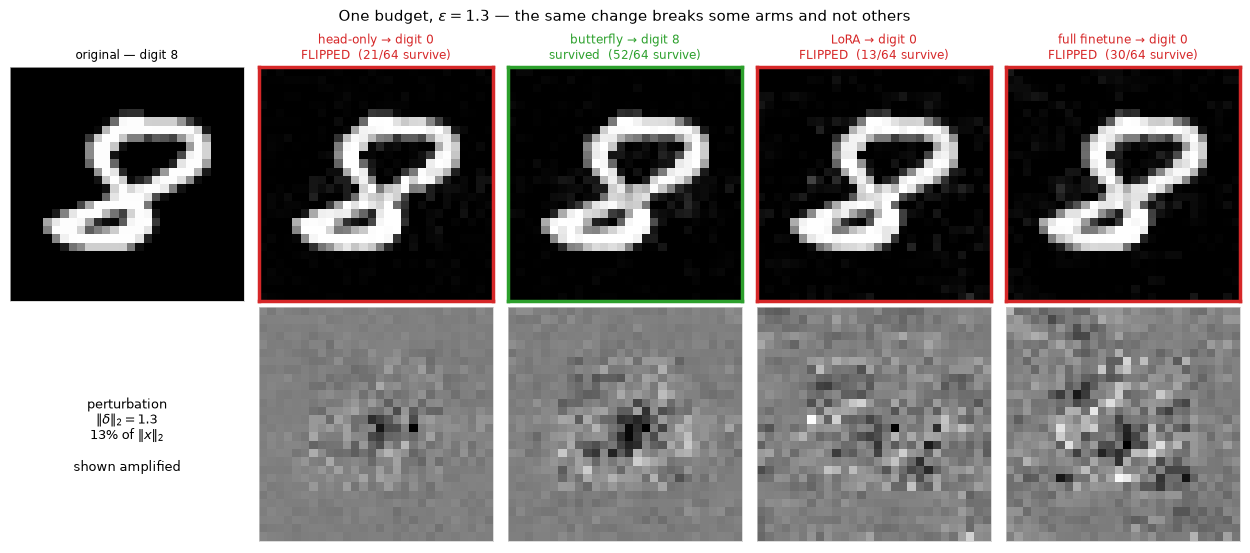

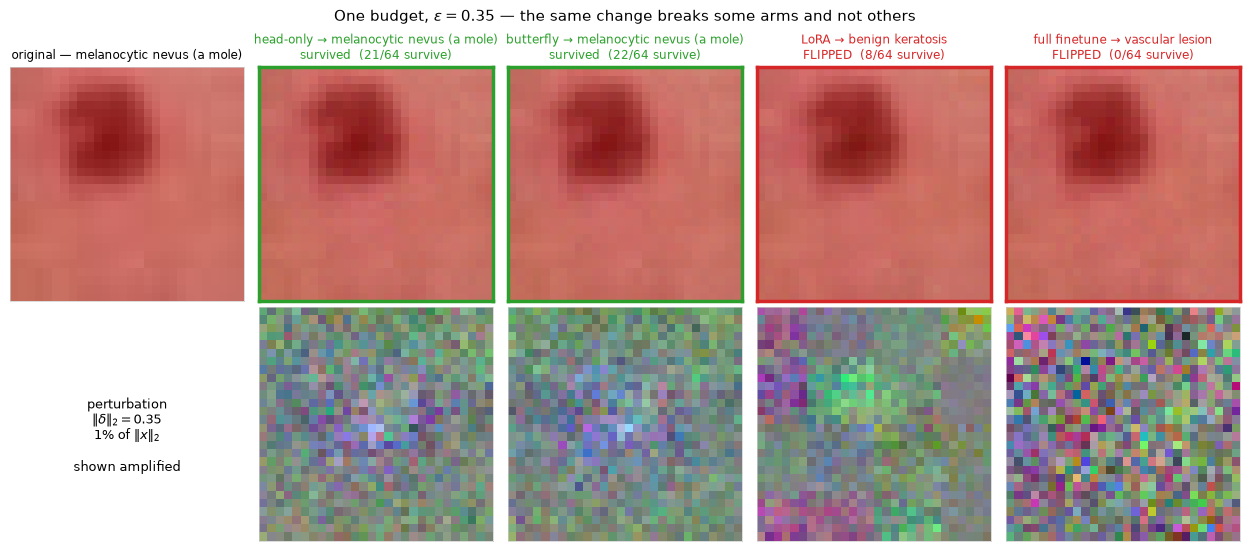

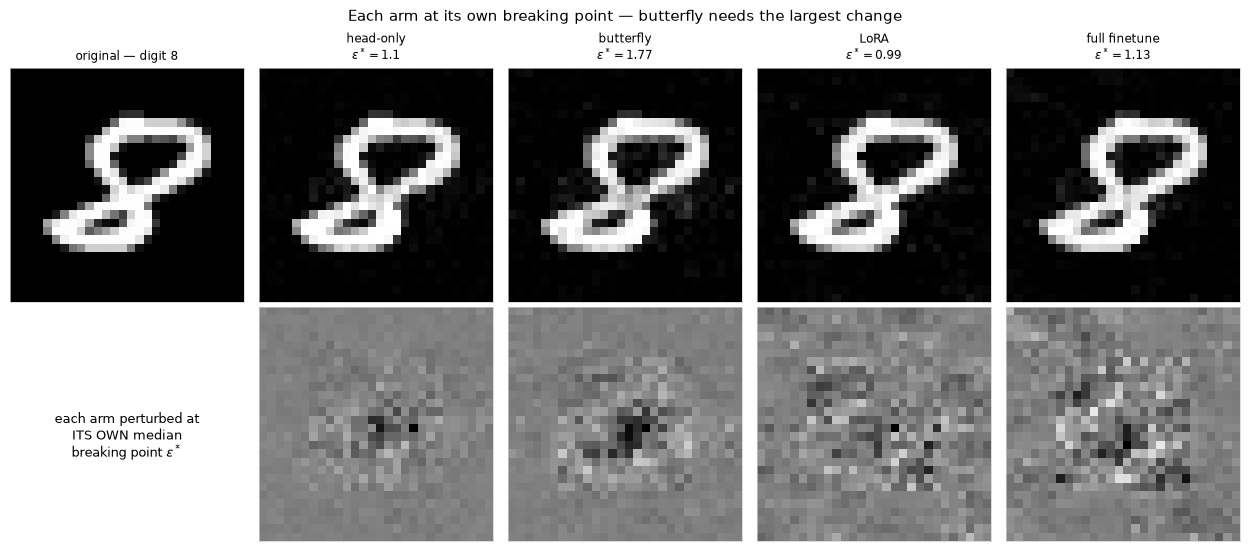

In [21]:
# Short labels: §6's legend names are too long for a five-panel strip.
# DermaMNIST classes, as MedMNIST names them. "class 5" is a mole.
DERMA_LABELS = ['actinic keratosis', 'basal cell carcinoma', 'benign keratosis',
                'dermatofibroma', 'melanoma', 'melanocytic nevus (a mole)',
                'vascular lesion']

LS = {'head-only': 'head-only', 'butterfly': 'butterfly',
      'lora': 'LoRA', 'full': 'full finetune',
      'dense': 'dense', 'dense-sn': 'dense + SN'}

def show_image(ax, img, title='', colour=None):
    """One panel. Handles greyscale and RGB, and frames flips in red."""
    im = np.clip(np.transpose(img, (1, 2, 0)) if img.shape[0] == 3 else img[0], 0, 1)
    ax.imshow(im, cmap=None if img.shape[0] == 3 else 'gray', vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=8.5, color=colour or 'black')
    for sp in ax.spines.values():
        sp.set_color(colour or '#cccccc'); sp.set_linewidth(2.5 if colour else 0.5)

def amplify(d):
    """A perturbation is invisible at its true scale; rescale it to fill [0, 1]."""
    return 0.5 + d / (2 * max(abs(d).max(), 1e-12))

def budget_figure(which):
    """One perturbation budget, applied to all four adapters of the same backbone."""
    f = np.load(f'results/figure_data_{which}.npz', allow_pickle=True)
    modes = [str(m) for m in f['modes']]
    i, eps, xn = int(f['chosen'][0]), float(f['shared_eps'][0]), float(f['x_norm'][0])
    lab = f['labels']
    name = ((lambda c: f'digit {lab[c]}') if lab.size
            else (lambda c: DERMA_LABELS[c]))
    x, y = f['x'], f['y']
    n = x.shape[0]

    fig, axes = plt.subplots(2, 5, figsize=(12.6, 5.6))
    show_image(axes[0, 0], x[i], f'original — {name(int(y[i]))}')
    axes[1, 0].axis('off')
    axes[1, 0].text(0.5, 0.45, f'perturbation\n$\\|\\delta\\|_2 = {eps}$\n'
                    f'{100 * eps / xn:.0f}% of $\\|x\\|_2$\n\nshown amplified',
                    ha='center', va='center', fontsize=9)
    for k, mode in enumerate(modes):
        d = f[f'delta_{mode}'][i]
        pred = int(f['preds'][0][k])
        broke = pred != int(y[i])
        show_image(axes[0, k + 1], np.clip(x[i] + d, 0, 1),
                   f'{LS[mode]} → {name(pred)}\n'
                   f"{'FLIPPED' if broke else 'survived'}  "
                   f"({n - int(f['counts'][k])}/{n} survive)",
                   '#d62728' if broke else '#2ca02c')
        show_image(axes[1, k + 1], amplify(d))
    fig.suptitle(f'One budget, $\\epsilon = {eps}$ — the same change breaks some arms '
                 f'and not others', fontsize=11)
    fig.tight_layout(); plt.show()

def own_eps_figure(which):
    """The same image at each arm's own breaking point: butterfly needs the most."""
    f = np.load(f'results/figure_data_{which}.npz', allow_pickle=True)
    modes = [str(m) for m in f['modes']]
    i = int(f['chosen'][0]); lab = f['labels']
    name = ((lambda c: f'digit {lab[c]}') if lab.size
            else (lambda c: DERMA_LABELS[c]))
    fig, axes = plt.subplots(2, 5, figsize=(12.6, 5.6))
    show_image(axes[0, 0], f['x'][i], f"original — {name(int(f['y'][i]))}")
    axes[1, 0].axis('off')
    axes[1, 0].text(0.5, 0.45, 'each arm perturbed at\nITS OWN median\nbreaking point $\\epsilon^*$',
                    ha='center', va='center', fontsize=9)
    for k, mode in enumerate(modes):
        dd = f[f'own_{mode}'][0]
        show_image(axes[0, k + 1], np.clip(f['x'][i] + dd, 0, 1),
                   f"{LS[mode]}\n$\\epsilon^* = {float(f['eps_star'][k])}$")
        show_image(axes[1, k + 1], amplify(dd))
    fig.suptitle('Each arm at its own breaking point — butterfly needs the largest change',
                 fontsize=11)
    fig.tight_layout(); plt.show()

budget_figure('mnist')
budget_figure('derma')
own_eps_figure('mnist')

## 8.4 Where the certificate stops: a change of lighting

The budgets above are tiny and pixel-shaped. The clinical question is different: what happens
under a change a *dermatoscope* could produce — a different lamp, a defocused lens, a tilted
probe, a different white balance?

`semantic_attack` optimises six such parameters by gradient ascent on the margin, inside ranges
a real device stays within, so it cannot leave the set of images a camera could have made.
`semantic_random` draws the same parameters uniformly: the same family, an average member
rather than its worst.

**DermaMNIST, accuracy after the change** (clean ≈ 0.52–0.60; `full` is 0.16):

| severity | | `head-only` | `butterfly` | `lora` | `full` | median $\|\delta\|_2$ |
|---|---|---|---|---|---|---|
| ¼ range | random draw | 0.602 | 0.594 | 0.555 | 0.141 | 1.11 |
| | **worst case** | 0.367 | **0.375** | 0.281 | 0.016 | 2.84 |
| ½ range | random draw | 0.578 | 0.609 | 0.562 | 0.148 | 2.46 |
| | **worst case** | 0.133 | **0.133** | 0.039 | 0.008 | 5.35 |
| full | random draw | 0.516 | 0.516 | 0.539 | 0.117 | 4.81 |
| | **worst case** | 0.000 | 0.000 | 0.000 | 0.000 | 10.4 |

Three readings, in order of how much they matter.

**1. Against `full`, yes. Against LoRA, not at all.** `full` collapses outright at every
severity and on every seed, so that gap is real and large. LoRA is a different story. The
single-seed numbers above (0.375 vs 0.281 at quarter severity, 0.133 vs 0.039 at half) look
decisive, and a paired McNemar test on those images gives $p \approx 10^{-5}$. Repeating the
whole thing six times says otherwise:

| severity | butterfly ahead on | sign test | mean difference |
|---|---|---|---|
| 0.1 | 3 of 6 seeds | $p = 1.00$ | — |
| 0.2 | 3 of 6 | $p = 1.00$ | — |
| 0.3 | **2 of 6** | $p = 0.69$ | +0.012 (seed sd 0.045) |
| 0.4 | 3 of 6 | $p = 1.00$ | +0.022 (seed sd 0.048) |
| 0.6 | 3 of 6 | $p = 1.00$ | — |

**There is no advantage over LoRA here.** The first seed we ran happened to be the most
favourable of six, and the per-image test reported that difference with enormous confidence
because it was measuring how far apart two *particular trained models* are — which retraining
dissolves. The honest unit of analysis is the seed, not the image, and at that resolution this
is a coin flip.

The ImageNet-scale replication agrees independently: the measured breaking point there is
0.78–1.09 across all six arms, with no separation. Two different setups, same answer.

One detail worth keeping: butterfly's seed-to-seed spread is **2–3× larger than LoRA's** (0.045
against 0.021 at severity 0.3), so the orthogonal adapter is the less stable of the two on this
task. Per-seed outcomes are in `results/acquisition_seed*.npz`.

**2. It matches, rather than beats, the frozen backbone.** `head-only` is within a couple of
points either way at every severity — differences of 38 against 43 images out of 128, inside
binomial noise. This is the conservation pattern again: butterfly keeps what the backbone had,
LoRA and `full` spend it. The reason to prefer butterfly over `head-only` is §6 and §8.2 —
larger radius, higher accuracy, same guarantee.

**3. The certificate does not reach this family.** The radius here is ≈ 0.5 and even the
mildest worst-case change has $\|\delta\|_2 = 2.84$, five times outside; the full-range one is
10.4. So nothing in this section is protected by the theorem — it is all measurement. §8.5
finds a family the theorem does reach.

And §5.4's lesson reproduces here unchanged: a **random** acquisition change costs every arm
under 8 points even at full severity; only the worst corner of the family bites. Random versus
worst-case is a property of high-dimensional families in general, not of $L_2$ balls.

DermaMNIST — accuracy after a change from the acquisition family:


random_draw                         worst_case                        
mode    head-only butterfly   lora   full  head-only butterfly   lora   full
scale                                                                       
0.25        0.602     0.594  0.555  0.141      0.367     0.375  0.281  0.016
0.50        0.578     0.609  0.562  0.148      0.133     0.133  0.039  0.008
1.00        0.516     0.516  0.539  0.117      0.000     0.000  0.000  0.000

median ||delta||_2 of that change (the certified radius is about 0.5):


random_norm                       worst_norm                       
mode    head-only butterfly  lora  full  head-only butterfly   lora  full
scale                                                                    
0.25         1.11      1.11  1.11  1.11       2.84      2.86   2.56  2.44
0.50         2.46      2.46  2.46  2.46       5.35      5.44   5.18  4.71
1.00         4.81      4.81  4.81  4.81       9.91     10.36  10.50  7.30

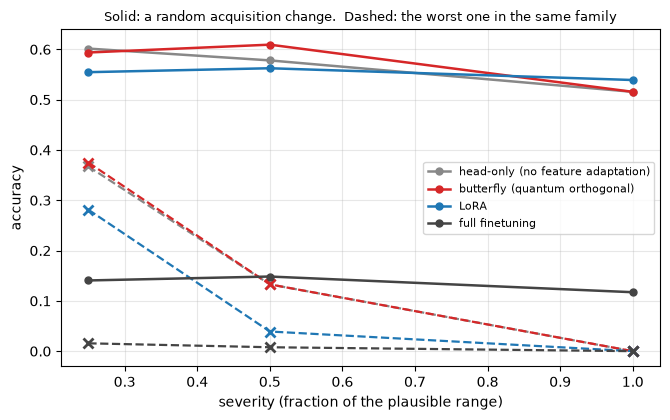

In [22]:
sg = pd.read_csv('results/semantic_grid.csv')
print('DermaMNIST — accuracy after a change from the acquisition family:')
display(sg.pivot_table(index='scale', columns='mode',
                       values=['random_draw', 'worst_case'])
        .reindex(columns=list(MODES), level=1).round(3))
print('median ||delta||_2 of that change (the certified radius is about 0.5):')
display(sg.pivot_table(index='scale', columns='mode',
                       values=['random_norm', 'worst_norm'])
        .reindex(columns=list(MODES), level=1).round(2))

fig, ax = plt.subplots(figsize=(6.8, 4.3))
for mode in MODES:
    s = sg[sg['mode'] == mode].sort_values('scale')
    ax.plot(s.scale, s.random_draw, '-o', color=CM[mode], lw=1.8, ms=5, label=LM[mode])
    ax.plot(s.scale, s.worst_case, '--x', color=CM[mode], lw=1.6, ms=7, mew=2)
ax.set_xlabel('severity (fraction of the plausible range)')
ax.set_ylabel('accuracy'); ax.grid(alpha=0.3)
ax.set_title('Solid: a random acquisition change.  Dashed: the worst one in the same family',
             fontsize=9.5)
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 8.5 What the certificate does cover: lossy image handling

§8.4's family is large in $L_2$ — a lamp change moves the image by 2.8 to 10, against a radius
of 0.5. But that is not the only thing that happens to a clinical image. A PACS re-encodes it
to JPEG, a viewer resizes it, a sensor adds read noise, a format stores 6 bits instead of 8.
Nobody calls those perturbations, and on real images they are **small**: if
$\|T(x) - x\|_2 < r(x)$, the certificate proves the diagnosis is unchanged, with no test
needed.

| DermaMNIST, fraction of images **provably** unaffected | `head-only` | `butterfly` | `lora` | `full` |
|---|---|---|---|---|
| JPEG q = 100 | 0.857 | 0.829 | **0.000** | **0.000** |
| JPEG q = 95 | 0.807 | 0.805 | **0.000** | **0.000** |
| JPEG q = 90 | 0.714 | 0.756 | **0.000** | **0.000** |
| JPEG q = 80 | 0.672 | 0.724 | **0.000** | **0.000** |
| 7-bit depth | 0.908 | 0.886 | **0.000** | **0.000** |
| 6-bit depth | 0.723 | 0.740 | **0.000** | **0.000** |
| resize 28→24→28 | 0.748 | 0.740 | **0.000** | **0.000** |
| resize 28→20→28 | 0.622 | 0.683 | **0.000** | **0.000** |
| sensor noise $\sigma = 0.005$ | 0.706 | 0.724 | **0.000** | **0.000** |

These are fractions *proved* safe, not accuracies. On MNIST the coverage is total: `butterfly`
certifies **100%** of images against JPEG at q ≥ 90, every bit-depth reduction and every noise
level tested. **LoRA and full fine-tuning prove nothing about any of it** — their radius is
0.000.

**What actually happens, as opposed to what is proved.** Empirically these operations are
nearly harmless for every arm: predictions change on 0–2% of images. You would discover that
by testing. Two things make the proof worth having anyway:

* You cannot spot-check every image a hospital system will ever re-encode, and a guarantee is
  what a regulator asks for.
* **The arm that proves nothing is the arm that misbehaves.** `full` fine-tuning changes
  **10.5%** of its predictions after a resize through 14×14 and 6.5% after JPEG q = 80, against
  `butterfly`'s 1.5% and 1.0%. The certificate is not a formality; it flags the model that is
  genuinely least reliable under ordinary handling.

So the deployable claim from this notebook is not "certified against attack". It is:

> **A model adapted with an orthogonal adapter can prove that JPEG re-encoding, bit-depth
> reduction, moderate resizing and sensor noise do not change its diagnosis — on about
> three-quarters of clinical images, and on all of them for easier tasks. A model adapted with
> LoRA or ordinary fine-tuning can prove none of it.**

Two limits. These are 28×28 crops and JPEG behaves differently on the 600×600 originals, so
this has to be re-measured at native resolution before anyone deploys on it. And a resize
through 14×14 falls outside the radius, so the claim covers lossy handling down to a stated
severity, not resampling in general.

In [23]:
pipe = pd.read_csv(PIPELINE_CSV)
OPS = ['jpeg q=100', 'jpeg q=95', 'jpeg q=90', 'jpeg q=80', '7-bit depth',
       '6-bit depth', 'resize 28->24->28', 'resize 28->20->28',
       'resize 28->14->28', 'sensor noise 0.002', 'sensor noise 0.005']

for ds in pipe.dataset.unique():
    d = pipe[pipe.dataset == ds]
    print(f'{ds} — fraction of images the certificate already proves unchanged:')
    display(d.pivot_table(index='operation', columns='mode',
                          values='certified_unchanged').loc[OPS, list(MODES)].round(3))

print('DermaMNIST — fraction whose prediction actually changed. '
      'The arm that proves nothing is also the one that moves most:')
display(pipe[pipe.dataset == 'dermamnist']
        .pivot_table(index='operation', columns='mode',
                     values='changed_prediction').loc[OPS, list(MODES)].round(3))

mnist08 — fraction of images the certificate already proves unchanged:


mode,head-only,butterfly,lora,full
operation,,,,
jpeg q=100,1.000,1.000,0.0,0.0
jpeg q=95,1.000,1.000,0.0,0.0
jpeg q=90,0.975,1.000,0.0,0.0
jpeg q=80,0.909,0.980,0.0,0.0
7-bit depth,1.000,1.000,0.0,0.0
6-bit depth,1.000,1.000,0.0,0.0
resize 28->24->28,0.497,0.879,0.0,0.0
resize 28->20->28,0.147,0.608,0.0,0.0
resize 28->14->28,0.005,0.080,0.0,0.0


dermamnist — fraction of images the certificate already proves unchanged:


mode,head-only,butterfly,lora,full
operation,,,,
jpeg q=100,0.857,0.829,0.0,0.0
jpeg q=95,0.807,0.805,0.0,0.0
jpeg q=90,0.714,0.756,0.0,0.0
jpeg q=80,0.672,0.724,0.0,0.0
7-bit depth,0.908,0.886,0.0,0.0
6-bit depth,0.723,0.740,0.0,0.0
resize 28->24->28,0.748,0.740,0.0,0.0
resize 28->20->28,0.622,0.683,0.0,0.0
resize 28->14->28,0.454,0.537,0.0,0.0


DermaMNIST — fraction whose prediction actually changed. The arm that proves nothing is also the one that moves most:


mode,head-only,butterfly,lora,full
operation,,,,
jpeg q=100,0.005,0.005,0.005,0.015
jpeg q=95,0.015,0.010,0.015,0.015
jpeg q=90,0.015,0.010,0.020,0.040
jpeg q=80,0.020,0.010,0.040,0.065
7-bit depth,0.005,0.000,0.005,0.005
6-bit depth,0.000,0.000,0.020,0.025
resize 28->24->28,0.010,0.005,0.010,0.040
resize 28->20->28,0.010,0.000,0.015,0.055
resize 28->14->28,0.025,0.015,0.025,0.105


# 9. Conclusions

## What these experiments support

1. **Orthogonality scales with depth where spectral normalisation does not.** Both enforce
   $L=1$, but only the orthogonal mixer preserves norm through repeated layers. `dense-sn`
   collapses beyond depth 32 on MNIST and at depth 16 on DermaMNIST, on every seed; `butterfly`
   is the only arm still learning at the deepest setting of either dataset. At depth 4 the two
   are indistinguishable, so this is a claim about depth, not about spectral normalisation.

2. **A certificate survives adaptation only under an orthogonal adapter.** $(RW)^\top(RW) =
   W^\top W$, so `butterfly` holds $L = 1.000000$ exactly while LoRA and full fine-tuning
   inflate it by three orders of magnitude on MNIST and by seven and nineteen on the clinical
   transfer. It beats `head-only` on accuracy as well, so it is genuinely adapting.

3. **The preserved bound is informative, not merely correct** (§8.2). `butterfly`'s certificate
   captures 92% of its true safe zone; `dense`'s is 95 trillion times too conservative, LoRA's
   300×, `full`'s $10^{18}$×. This is the answer to the obvious objection that preserving $L$ is
   bookkeeping.

4. **Whether it is harder to attack depends on what the loss demands** (§8.2). Asked for the
   same *margin* — what ordinary fine-tuning does — `butterfly` is 2.3× harder to break than
   LoRA, six seeds of six. Asked for the same *certified radius*, the objective charges LoRA for
   its inflated $L$, LoRA compensates with larger margins, and the ImageNet-scale replication
   measures it 10–35% ahead instead. Both are real; they answer different questions. The
   certificate does not depend on the choice: $L/L_0 = 1.000000$ for `butterfly` under either.

5. **The radius is trainable, and the adapter has headroom the backbone does not** (§5.6).
   Asking the loss for a larger margin more than doubles the certified radius at no cost in
   accuracy — 0.42 → 0.92 over three seeds. `head-only` saturates at 0.45 because it can only
   move the final layer; `butterfly` keeps going because it can rotate the representation too.
   That is a reason to prefer the orthogonal adapter that has nothing to do with preserving
   $L$.

6. **The advantage is worst-case, not average-case.** Random perturbations separate nothing,
   anywhere, at any size (§5.4, §7.3), and the same turns out to be true inside a family of
   realistic acquisition changes (§8.5).

## What they do not support, and one thing that refutes it

* **Orthogonality conserves robustness; it never creates it.** Every result above is of the form
  "kept what the backbone had while the alternatives spent it".
* **The certificate does not reach clinical variation** (§8.4). A plausible change of exposure
  or white balance has an $L_2$ norm 5–20× larger than the certified radius, and the worst such
  change takes every arm — `butterfly` included — to zero accuracy. It *does* reach ordinary
  lossy image handling (§8.5), which is a smaller claim and a true one.
* **Orthogonality cannot *learn* invariance.** If the backbone and adapter are retrained with
  random acquisition augmentation, every arm improves — `butterfly` sevenfold at severity 0.6 —
  but **LoRA improves most and overtakes everything**, on clean accuracy too. Invariance to a
  nuisance factor means *contracting* the directions it moves in, and an orthogonal map cannot
  contract anything; $L = 1$ *is* the promise never to contract. **The property that preserves
  the proof is the property that prevents the learned invariance.** So the method's place is
  where you need a guarantee you did not have to train for, not where augmentation is available
  and sufficient. (`results/semantic_augmented.csv`.)
* Fewer trainable parameters do not imply lower compute: the butterfly still materialises and
  applies a dense matrix.
* **Scale and split.** Everything here is 28×28, two seeds, and MedMNIST's image-level splits.
  DermaMNIST's originals are 600×450, and §8.5's JPEG result in particular has to be
  re-measured at native resolution before it is a deployment claim.

## So what is it for

Not "quantum-inspired layers are robust" — nothing here supports that. The defensible claim is
narrower and still useful:

> **Orthogonal adaptation is the only method we tested that moves a certified model to a new
> task without spending its certificate, at no cost in accuracy.**

The one deployable form of that found here is §8.5: an orthogonally adapted model can **prove**
that JPEG re-encoding, bit-depth reduction, moderate resizing and sensor noise leave its
diagnosis unchanged, on about three-quarters of clinical images and on all of them for easier
tasks, where LoRA and full fine-tuning prove none of it. That is reproducibility under lossy
handling, not robustness against an adversary — and it is the version a hospital can use.

Use it when you need a *proof* — a deterministic guarantee you can hand to a regulator. Use
augmentation, and an adapter free to contract, when you need *invariance* to how the image was
captured. The exchange rate on this task, measured, is about 11 points of
worst-case acquisition robustness at severity 0.6 against a certificate. Having both would
need the contraction to live somewhere other than the certified path — the most interesting
thing this notebook does not test.

# 10. Next steps

The MNIST experiments establish the mechanism and section 7 shows it survives a small, imbalanced, multiclass clinical dataset. The next step is to test whether it remains useful at realistic **scale** and **resolution**.

## 10.1 Validate on a real certified backbone

Use an ImageNet-scale certified model such as BRONet and first reproduce its reported certificate before any adaptation.

Then attach orthogonal butterfly adapters to the channel-mixing layers and compare:

* `head-only`
* `butterfly`
* `lora`
* `full`

The main question is whether the butterfly adapter still preserves the backbone's Lipschitz bound exactly while allowing useful adaptation.

Real backbones also introduce practical issues such as non-power-of-two channel widths, which may require padding or a more general butterfly construction.

## 10.2 Test whether the certified representation is good enough

Certificate preservation is only useful if the pretrained representation transfers well.

The key comparison is therefore between a strong standard ImageNet backbone and a certified one, evaluated with the same downstream task, adaptation strategy, and patient-level cross-validation.

This separates two questions:

1. Does the adapter preserve the certificate?
2. What downstream accuracy is lost by starting from a certified backbone?

If the second cost is too large, the method may remain interesting as a robustness result without being competitive for clinical deployment.

## 10.3 Evaluate on clinical data

Section 7 is a first step in this direction, but a limited one: DermaMNIST is 28×28 (the HAM10000 originals are 600×450), and MedMNIST's splits are image-level, not patient-level. A serious evaluation should focus on:

* **patient-level splits**, never image-level splits;
* **per-class performance**, especially for rare classes;
* **certified radius and adversarial robustness**;
* comparison with realistic corruptions such as illumination, blur, compression, and acquisition-device changes.

The last comparison is important because an $L_2$ certificate does not guarantee robustness to these forms of distribution shift.

## 10.4 Main research question

The most interesting direction is not whether quantum-inspired networks are generally more robust, but whether:

> **Orthogonal quantum-inspired adapters can adapt a certified pretrained model to a new task without losing its deterministic robustness guarantee.**

The largest remaining uncertainty is scale: whether the certificate-preserving mechanism demonstrated here continues to work with realistic pretrained models, substantial domain shifts, and limited clinical data.


# Appendix: Running on another dataset

**MedMNIST datasets are already supported.** Any of `dermamnist`, `bloodmnist`,
`pathmnist`, `octmnist`, `organamnist`, `pneumoniamnist`, `retinamnist` or
`breastmnist` can be passed as a dataset name; the images are downloaded on first use.
Both section 7 experiments reduce to two commands:

```bash
python experiments.py --experiment depth --dataset dermamnist \
    --depths 4 16 32 64 --epochs 30 --class-weights --out-prefix derma_
python experiments.py --experiment adaptation --source bloodmnist \
    --target dermamnist --epochs 30 --class-weights --out-prefix derma_
```

`--class-weights` weights the loss by inverse class frequency and should be used on
any imbalanced dataset — without it, *no* arm learns DermaMNIST. `--out-prefix`
keeps the results in their own files.

**For a dataset that is not MedMNIST**, implement `build_loaders(...)` in `core.py` so
that it returns:

```python
{
    'train': DataLoader,
    'test': DataLoader,
    'eval': DataLoader,
    'num_classes': int,
    'in_channels': int,
    'sizes': {...}
}
```

Each loader should return `(x, y)`, with `x` shaped `(B, C, H, W)`.

If perturbation radii should remain directly interpretable in pixel space, keep inputs
scaled to $[0,1]$ without mean/std normalisation.

Then run:

```python
from experiments import run_grid

run_grid(dataset='your_dataset', arms=ARMS, depths=(4, 32, 128),
         seeds=3, epochs=10, class_weights=False)
```

Channel width is chosen automatically by `core.channels_for`: the smallest power-of-two
lift with `lift >= in_channels`, times 64. That is 64 channels for greyscale and 256 for
RGB. The lift is an orthonormal `eye(lift, in_channels)`, so it is an isometry and
contributes exactly 1 to the Lipschitz bound. The butterfly implementation requires the
mixer width to be a power of two, which this construction guarantees.